# Imports

In [495]:
import pandas as pd
import numpy as np
import sys
import os
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv
from scipy.stats import pearsonr
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score


sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

# Variables

In [496]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_output = '../../../1_allele_collection/3_outputs'

In [497]:
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']
aa_id = 0
rrs_id = 999999.0
max_score = 800
max_size = 1200
min_growth_score = 200
original_datafile_path = 'sqY2H_manual_automated_annotated_scores_size.csv'
tracking_dict = {}

# Single functions

In [498]:
def pull_numbers(df, verbose=False):
    df = pl.DataFrame(df)
    
    if 'per_well_integrated_intensity_gray' in df.columns:
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_null())
        df = df.filter(pl.col('per_well_integrated_intensity_gray').is_not_nan())
    
    if 'consensus_score' in df.columns:
        df = df.filter(pl.col('consensus_score').is_not_null())
        df = df.filter(pl.col('consensus_score').is_not_nan())
    
    dbs = df.select(pl.col('db_orf_id')).n_unique()
    ads = df.select(pl.col('ad_orf_id')).n_unique()
    
    df = df.with_columns(
        pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group"),
            pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    )
    
    muts = df.filter(pl.col('db_mut_id') != 0).select(pl.col('db_mut_id')).n_unique()
    
    if verbose:
        print('Number of rows:', df.height)
    
    return {'dbs': dbs, 'ads': ads, 'alleles': muts, 'edges': df.select(pl.col('edge_group')).n_unique(), 'ppis': df.select(pl.col('ppi_group')).n_unique()}

In [499]:
def load_original_dataframe(file_path, inputs_dir=inputs_dir, tracking_dict=tracking_dict):
    df = pd.read_csv(os.path.join(inputs_dir, file_path))
    
        
    # cast all to same format
    df['ad_orf_id'] = pd.to_numeric(df['ad_orf_id'], errors='coerce')
    df['db_orf_id'] = pd.to_numeric(df['db_orf_id'], errors='coerce')
    df['db_mut_id'] = pd.to_numeric(df['db_mut_id'], errors='coerce')


    return df, tracking_dict
    


In [500]:
orig_df, tracking_dict = load_original_dataframe(file_path=original_datafile_path)

In [501]:
def initial_qaqc(df, tracking_dict=tracking_dict):
    # Remove rows where manual_score_growth is NaN because those wells are flagged as contamination
    # do not drop but replace the automatic scores by nan
    
    df['contamination'] = df['manual_score_growth'].isna()
    df.loc[df['manual_score_growth'].isna(), 'per_well_integrated_intensity_gray'] = np.nan

    tracking_dict['1. Initial data'] = pull_numbers(df, verbose=False)
    
    # Remove wrongly mapped wells with abnormally high automated scores
    df['outlier_score'] = df['per_well_integrated_intensity_gray'] > max_score
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    
    # Remove wrongly mapped wells with abnormaylly high size
    df['outlier_size_score'] = df['total_colony_area'] > max_size
    df['per_well_integrated_intensity_gray'] = df.apply(lambda row: np.nan if row['outlier_size_score'] else row['per_well_integrated_intensity_gray'], axis=1)
    

    # size score calculation
    df['size_score_raw'] = df['per_well_integrated_intensity_gray'] * df['total_colony_area']
    
    # Size score normalization
    # Size of best growth (manual score 4) median
    max_size_score = df[df.manual_score_growth == 4].total_colony_area.median()
    df['size_score'] = (df['size_score_raw'] / max_size_score)
    
    tracking_dict['2. After intensity and size filtering'] = pull_numbers(df, verbose=False)
    
    
    return df, tracking_dict


In [502]:
init_df, tracking_dict = initial_qaqc(orig_df, tracking_dict=tracking_dict)

init_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,ad_source_well,per_well_integrated_intensity_gray,manual_score_growth,total_colony_area,Children_reExpandedColonies_Count,contamination,outlier_score,outlier_size_score,size_score_raw,size_score
0,VUSAPWT1B1r01_001,A01,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,A10,490.572572,4.0,963,1,False,False,False,472421.386937,438.645670
1,VUSAPWT1B1r01_001,A02,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,True,NaN,NaN,...,A10,521.929437,4.0,1032,1,False,False,False,538631.178658,500.121800
2,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,455.656230,4.0,899,1,False,False,False,409634.951014,380.348144
3,VUSAPWT1B1r01_001,A04,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,544.304600,4.0,1050,1,False,False,False,571519.830157,530.659081
4,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,A01,505.925513,4.0,970,1,False,False,False,490747.747580,455.661790
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306426,VUSAPWT1B1r06_036,P20,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,435.596088,2.0,962,2,False,False,False,419043.436190,389.083970
306427,VUSAPWT1B1r06_036,P21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,NaN,2.0,1642,2,False,True,True,NaN,NaN
306428,VUSAPWT1B1r06_036,P22,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,E11,NaN,2.0,1637,3,False,True,True,NaN,NaN
306429,VUSAPWT1B1r06_036,P23,VUSAPWT1B1r06_031_032_033_034_035_036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,12,1,True,False,False,NaN,NaN


## Consensus

In [503]:
def consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=False):
    """
    Calculate consensus scores from replicates with outlier correction.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Input dataframe with replicate measurements
    tracking_dict : dict
        Dictionary to track processing steps
    use_median : bool
        If True, use median instead of mean for consensus scores (default: False)
    
    Returns:
    --------
    tuple : (df, tracking_dict)
    """
    
    def correct_scores_by_manual(scores, manual_scores, central_value):
        """Keep scores that align with manual scoring pattern."""
        scores = np.array(scores)
        manual_scores = np.array(manual_scores)
        
        manual_mean = np.mean(manual_scores)
        expect_high = manual_mean > 2
        expect_middle = manual_mean == 2
        
        if expect_high:
            mask = scores >= central_value
        elif expect_middle:
            tolerance = 0.50 * min_growth_score
            mask = (scores >= (min_growth_score - tolerance)) & (scores <= (min_growth_score + tolerance))
        else:
            mask = scores <= central_value
        
        corrected_scores = scores[mask].tolist()
        return corrected_scores

    mads = []
    mads_dict = {}

    # STEP 1: Build dictionary with initial corrections
    for group, group_df in df.groupby(['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']):
        manual_scores = group_df['manual_score_growth'].dropna().values.tolist()
        scores = group_df['size_score'].dropna().values.tolist()
        median = np.median(scores)
        mean = np.mean(scores)
        mad = np.median(np.abs(scores - median))
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        # Handle groups with <4 replicates AND mad == 0
        if len(scores) < 4 and len(scores) > 1 and mad == 0:
            max_diff = np.max(np.abs(np.array(scores)[:, None] - np.array(scores)))
            
            if max_diff > min_growth_score:
                corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
                if corrected_scores:
                    corrected_central = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
                else:
                    corrected_central = np.nan
            else:
                corrected_central = central_value
                
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': corrected_central,  # Name kept for compatibility
                'manual_scores': manual_scores,
                'already_corrected': True
            }
        else:
            # All other groups
            mads.append(mad)
            mads_dict[group] = {
                'MAD': mad, 
                'scores': scores,
                'mean': mean,
                'median': median,
                'corrected_mean': None,
                'manual_scores': manual_scores,
                'already_corrected': False
            }

    # STEP 2: Calculate MAD threshold
    mads_no_nan = [mad for mad in mads if not np.isnan(mad)]
    mad_95 = np.percentile(mads_no_nan, 95) if mads_no_nan else np.inf
    # print(f"95th percentile of MADs: {mad_95}")
    # print(f"Using {'median' if use_median else 'mean'} for consensus scores")
    
    # STEP 3: Apply corrections to high-MAD groups (skip already corrected)
    for group, values in mads_dict.items():
        if values['already_corrected']:
            continue
        
        mad_value = values['MAD']
        scores = values['scores']
        mean = values['mean']
        median = values['median']
        manual_scores = values['manual_scores']
        
        # Choose central tendency measure
        central_value = median if use_median else mean
        
        if mad_value > mad_95:
            corrected_scores = correct_scores_by_manual(scores, manual_scores, central_value)
            if corrected_scores:
                values['corrected_mean'] = np.median(corrected_scores) if use_median else np.mean(corrected_scores)
            else:
                values['corrected_mean'] = np.nan
        else:
            values['corrected_mean'] = central_value

    # STEP 4: Convert to DataFrame
    corrected_df = pd.DataFrame([
        {
            'ad_orf_id': group[0],
            'db_orf_id': group[1],
            'db_mut_id': group[2],
            'condition_name': group[3],
            'retest_batch': group[4],
            'corrected_mean': values['corrected_mean']
        }
        for group, values in mads_dict.items()
        if values['corrected_mean'] is not None and not np.isnan(values['corrected_mean'])
    ])

    # STEP 5: Merge and finalize
    df = df.merge(
        corrected_df,
        on=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch'],
        how='left',
        suffixes=('', '_corrected')
    )

    df['consensus_score'] = df['corrected_mean'].fillna(np.nan)
    df.drop('corrected_mean', axis=1, inplace=True)
    
    df = df.drop_duplicates(subset=['ad_orf_id', 'db_orf_id', 'db_mut_id', 'condition_name', 'retest_batch']).reset_index(drop=True)
    
    tracking_dict['3. After consensus score calculation'] = pull_numbers(df, verbose=False)
    
    return df, tracking_dict

In [504]:
cons_df, tracking_dict = consensus_score_calculation(init_df, tracking_dict=tracking_dict, use_median=True)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## Metadata

In [505]:

def metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    # Cast join keys to string for mapping (always cast to string for consistent joining)
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    }).with_columns([
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.String),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.String)
    ])
    
    # Merge with metadata
    df_pl = df_pl.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
    
    # Restore original dtypes for db_orf_id and db_mut_id
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(original_db_orf_dtype),
        pl.col("db_mut_id").cast(original_db_mut_dtype)
    ])
    

    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [506]:
def metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir, map_ad_symbol=True):
    """
    Map AD symbols and merge with metadata for the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe with ad_orf_id, db_orf_id, db_mut_id columns
    meta_output : str
        Path to metadata output directory
    inputs_dir : str
        Path to inputs directory containing mapping file
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        DataFrame with added ad_symbol and metadata columns (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for efficient processing
    df_pl = pl.DataFrame(df) if not input_is_polars else df
    
    # Store original dtypes for db_orf_id and db_mut_id
    original_db_orf_dtype = df_pl["db_orf_id"].dtype
    original_db_mut_dtype = df_pl["db_mut_id"].dtype
    
    if map_ad_symbol:
        # Load AD ORF ID to symbol mapping
        mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
        mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
        mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()
        
        # Map AD ORF IDs to symbols
        df_pl = df_pl.with_columns(
            pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
        )
    
    
    # Cast as int then string for joining
    df_pl = df_pl.with_columns([
        pl.col("db_orf_id").cast(pl.Float64),
        pl.col("db_mut_id").cast(pl.Float64)
    ])
    
    # Separate WT and variant rows
    df_wt = df_pl.filter(pl.col("db_mut_id") == 0)
    df_variants = df_pl.filter(pl.col("db_mut_id") != 0)
    
    # Load metadata
    metadata_path = f"{meta_output}/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI.tsv"
    metadata = pl.read_csv(
        metadata_path, 
        separator="\t", 
        infer_schema_length=None
    ).rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id"
    })
    
    # For variants: full join on both db_orf_id and db_mut_id
    if df_variants.height > 0:
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        metadata_variants = metadata.with_columns([
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String),
            pl.col("db_mut_id").cast(pl.Int64).cast(pl.String)
        ])
        
        df_variants = df_variants.join(metadata_variants, on=["db_orf_id", "db_mut_id"], how="left")
        
        df_variants = df_variants.with_columns([
            pl.col("db_orf_id").cast(original_db_orf_dtype),
            pl.col("db_mut_id").cast(original_db_mut_dtype)
        ])
    
    # For WT: join only on db_orf_id to get symbol and other gene-level info
    if df_wt.height > 0:
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        # Get unique gene-level metadata (just db_orf_id and symbol, plus other gene-level columns)
        metadata_wt = metadata.select([
            "db_orf_id", "symbol"
        ]).unique(subset=["db_orf_id"]).with_columns(
            pl.col("db_orf_id").cast(pl.Int64).cast(pl.String)
        )
        
        df_wt = df_wt.join(metadata_wt, on="db_orf_id", how="left")
        
        df_wt = df_wt.with_columns(
            pl.col("db_orf_id").cast(original_db_orf_dtype)
        )
    
    # Combine WT and variant rows back together
    if df_wt.height > 0 and df_variants.height > 0:
        df_pl = pl.concat([df_wt, df_variants], how="diagonal")
    elif df_variants.height > 0:
        df_pl = df_variants
    else:
        df_pl = df_wt
        
        
    # Consolidate clinvar_clnsig_clean_pp_strit column into clinvar_clnsig_clean, merging likely benign and benign as well as likely pathogenic and pathogenic
    
    
    df_pl = df_pl.with_columns(
        pl.when(
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Benign")) | 
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely benign"))
        ).then(pl.lit("Benign"))
        .when(
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Pathogenic")) | 
            (pl.col("clinvar_clnsig_clean_pp_strict") == pl.lit("Likely pathogenic"))
        ).then(pl.lit("Pathogenic"))
        .otherwise(pl.col("clinvar_clnsig_clean_pp_strict"))
        .alias("clinvar_clnsig_clean")
    )
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [507]:
meta_df = metadata_mapping(cons_df, meta_output=meta_output, inputs_dir=inputs_dir)

## Splicing

In [508]:
def remove_splicing_variants(df):
    """
    Remove splicing variants and Met1xxx from the dataframe.
    
    Parameters:
    -----------
    df : pd.DataFrame or pl.DataFrame
        Input dataframe containing splicing_variant column
        
    Returns:
    --------
    pd.DataFrame or pl.DataFrame
        Filtered dataframe (same type as input)
    """
    # Track input type to return the same type
    input_is_polars = isinstance(df, pl.DataFrame)
    
    # Convert to polars for filtering
    if input_is_polars:
        df_pl = df
    else:
        df_pl = pl.DataFrame(df)
    
    # Filter out splicing variants
    df_pl = df_pl.filter(
        (pl.col('splicing_variant') == False) | 
        (pl.col('splicing_variant').is_null())
    )
    
    # Filter out Met1xxx variants (e.g., Met1Ala, Met1Val, etc.)
    # Keep rows where aa_change is null OR doesn't match the pattern
    df_pl = df_pl.filter(
        pl.col('aa_change').is_null() | 
        ~pl.col('aa_change').str.contains(r'^Met1[A-Z][a-z]{2}$')
    )
    
    # Convert back to pandas if input was pandas
    if input_is_polars:
        return df_pl
    else:
        return df_pl.to_pandas()

In [509]:
meta_df = remove_splicing_variants(meta_df)
meta_df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
0,VUSAPWT1B1r01_001,A03,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,NaN,None,None,None,None,None,None,NaN,None,None
1,VUSAPWT1B1r01_001,A05,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,NaN,None,None,None,None,None,None,NaN,None,None
2,VUSAPWT1B1r01_001,A09,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,NaN,None,None,None,None,None,None,NaN,None,None
3,VUSAPWT1B1r01_001,A11,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,15066.0,NaN,...,NaN,None,None,None,None,None,None,NaN,None,None
4,VUSAPWT1B1r01_001,A13,VUSAPWT1B1r01_001_002_003_004_005_006,VUSAPWT1B1,r07,LW,1.0,False,0.0,NaN,...,NaN,None,None,None,None,None,None,NaN,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72919,VUSAPWT1B1r06_036,O17,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,53212.0,NaN,...,44.339622,>90,10-90,609040,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy,2.0,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False
72920,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,3.045685,>90,<10,None,None,None,Rare genetic cardiac disease; Laminopathy,2.0,None,False
72921,VUSAPWT1B1r06_036,O19,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,3.045685,>90,<10,None,None,None,Rare genetic cardiac disease; Laminopathy,2.0,None,False
72922,VUSAPWT1B1r06_036,O21,VUSAPWT1B1r06_031_032_033_034_035_036,VUSAPWT1B1,r12,LWAH1,1.0,False,100069191.0,NaN,...,5.325444,>90,<10,609040,autosomal dominant,OMIM,Rare genetic cardiac disease; Laminopathy,2.0,"ARRHYTHMOGENIC RIGHT VENTRICULAR DYSPLASIA, FA...",False


## Seq

In [510]:
def sequencing_filtering(df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir):
    scores = df.copy()

    scores = scores[scores['media_control'] == False]
    
    # Fix data types before converting to polars
    scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
    scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
    scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
    scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
    scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

    # add IDs for groups used for filtering
    scores = pl.DataFrame(scores)

    scores = scores.with_columns(
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    )

    scores = scores.with_columns(
        pl.concat_str([
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("db_group"),
        pl.concat_str([
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('condition_name').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("db_condition_group"),
        pl.concat_str([
                pl.col('ad_orf_id').cast(pl.String),
                pl.col('db_orf_id').cast(pl.String),
                pl.col('db_mut_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("ppi_group"),
        pl.concat_str([
                pl.col('ad_orf_id').cast(pl.String),
                pl.col('db_orf_id').cast(pl.String),
                pl.col('retest_batch').cast(pl.String)
        ], separator="_").alias("edge_group")
    )
        
    # read in sequence confirmation files
    ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
        "swim_seq_validated": "seq_ad"
    }).select([
        "ad_orf_id", "assay_id", "seq_ad"
    ])

    db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
        "orf_id": "db_orf_id",
        "mut_id": "db_mut_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
        "disease_orf_id": "db_orf_id",
        "swim_seq_validated": "seq_db"
    }).select(["db_orf_id", "seq_db"]).with_columns(
        pl.lit(0).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "seq_db"])

    db_seq = pl.concat([db_var_seq, db_ref_seq])


    # cast all to same format
    scores = scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    db_seq = db_seq.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("seq_db").cast(pl.String).alias("seq_db")
    )

    ad_seq = ad_seq.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
        pl.col("assay_id").cast(pl.String).alias("assay_id"),
    )

    scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
    scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

    final_sequencing_df = pd.read_csv(f"{meta_output}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)


    # Convert final_sequencing_df to polars and ensure matching data types
    final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
    ).select(["db_orf_id", "db_mut_id", "db_seq_final"])

    # Join the db_seq_final column onto scores
    scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

    scores_aa_rrs = scores.filter(
        (pl.col("ad_orf_id") == aa_id) | 
        (pl.col("db_mut_id") == rrs_id)
    )

    scores = scores.filter(
        (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
        (
            (pl.col("db_mut_id") == 0) |  # WT is always good
            (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
        )
    )

    scores = pl.concat([scores, scores_aa_rrs])
    
    tracking_dict['4. After sequencing'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [511]:
seq_df, tracking_dict = sequencing_filtering(meta_df, tracking_dict=tracking_dict, meta_output=meta_output, inputs_dir=inputs_dir)

## QAQC

In [512]:
def qa_qc_filtering(df, tracking_dict=tracking_dict, min_growth_score=min_growth_score):


    scores = df


    # Remove all db groups with the same allele if there was an autoactivation mating failure
    aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                .filter(pl.col("condition_name") == "LW")
                                .filter(pl.col("consensus_score") <= min_growth_score)
                                .select("db_group")
                                .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))


    # Remove all db-condition groups with the same allele if there was an autoactivation mating failure
    aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                    .filter(pl.col("consensus_score").is_nan())
                                    .select("db_condition_group")
                                    .to_series().unique().to_list())
    scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))


    tracking_dict['5. Autoactivation mating filtering'] = pull_numbers(scores, verbose=False)
    
    # Remove mating failures - condition LW with low/null consensus score
    mating_failures = (scores.filter(
                            (pl.col("condition_name") == "LW") & 
                            ((pl.col("consensus_score") <= min_growth_score) | pl.col("consensus_score").is_null())
                        )
                        .select("ppi_group")
                        .to_series()
                        .unique()
                        .to_list())
    scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

    tracking_dict['6. Mating filtering'] = pull_numbers(scores, verbose=False)

    # Calculate aa_score per condition as the mean of the aa scores in that condition
    aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
        "db_condition_group", "consensus_score"
    ]).group_by("db_condition_group").agg(
        pl.col("consensus_score").mean().alias("aa_score")  # or .first() if you want the first value
    )

    # Add the aa_score to the dataframe, merged on the condition-specific db allele
    scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group", how="left")

    # Remove autoactivation by checking empty-AD scores
    scores = scores.filter(
        (pl.col("condition_name") == "LW") |          # keep all LW
        pl.col("aa_score").is_null() |                # or no AA score
        (pl.col("aa_score") <= min_growth_score)       # or AA score acceptable
    )
    
    # Keep only scores that aren't RRS pairs
    scores = scores.filter(pl.col('db_mut_id') != rrs_id)

    scores = scores.with_columns(
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
    )


    tracking_dict['7. Autoactivation filtering'] = pull_numbers(scores, verbose=False)
    

    # Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter(
                                    (pl.col("consensus_score") <= min_growth_score) | 
                                    pl.col("consensus_score").is_null()
                                )
                                .select('edge_group')
                                .to_series().unique().to_list())
    
    scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))
    
        
    manual_scores = pl.read_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

    manual_scores = manual_scores.with_columns(
        pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
        pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id"),
        pl.col("consensus_score").alias("consensus_manual_score_growth")
    )

    # join to scores
    scores = scores.join(manual_scores.select([
        "ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name", "consensus_manual_score_growth"
    ]), on=["ad_orf_id", "db_orf_id", "db_mut_id", "assay_id", "condition_name"], how="left")

    tracking_dict['8. After WT filtering'] = pull_numbers(scores, verbose=False)


    return scores, tracking_dict

In [513]:
df, tracking_dict = qa_qc_filtering(seq_df, tracking_dict=tracking_dict)

## Select best media

In [514]:
def select_best_media(df, scoring_conditions=scoring_conditions, min_growth_score=min_growth_score, verbose=False, tracking_dict=tracking_dict):

    scores_pd = df.to_pandas()

    # retain only scoring conditions
    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]

    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]  # remove NaNs

    # First, build WT media dict as fallback
    wt_media_dict = {} 

    for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
        for media in scoring_conditions:
            media_scores = df[df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                wt_media_dict[edge] = media

    # Now build benign media dict
    benign_media_dict = {}

    for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "Benign"].groupby("edge_group"):
        var_dict = {}
        for ppi, ppi_df in df.groupby("ppi_group"):
            var_dict[ppi] = []
            for media in scoring_conditions:
                media_scores = ppi_df[ppi_df.condition_name == media]
                if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                    var_dict[ppi].append(media)
                    
        if len(var_dict) == 1:
            # only one variant for this edge, take the last media where it grew
            for ppi, media_list in var_dict.items():
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
        elif len(var_dict) > 1:
            # multiple benign variants. Take the last media of the most sensible variant (the one that grew in the least media)
            sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
            for ppi, media_list in sorted_variants:
                if media_list:
                    benign_media_dict[edge] = media_list[-1]
                    break        

    # Combine benign and WT media dicts with benign taking priority
    combined_media_dict = {}
    for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
            # print(f"Edge {edge}: Using benign methodology -> {benign_media_dict[edge]}")
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
            # print(f"Edge {edge}: Fallback to WT methodology -> {wt_media_dict[edge]}")
        # If edge is in neither dict, it will be skipped
    
    if verbose:
        print(f"Total edges with benign variants: {len(benign_media_dict)}")
        print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
        print(f"Total edges covered: {len(combined_media_dict)}")


                
    # Now filter all scores to only include the best medium per edge
    filtered_scores = []
    for edge, df in scores_pd.groupby("edge_group"):
        if edge in combined_media_dict:
            valid_media = combined_media_dict[edge]
            filtered_df = df[df.condition_name == valid_media]
            filtered_scores.append(filtered_df)
            
    if filtered_scores:
        filtered_scores = pd.concat(filtered_scores, ignore_index=True)
        if verbose:
            print(f"Filtered scores shape: {filtered_scores.shape}")
    
    # filter for edges with at least a variant and a WT
    if verbose:
        print(f"Total unique ppis before filtering: {filtered_scores['ppi_group'].nunique()}")
    valid_edges = filtered_scores.groupby("edge_group").filter(lambda x: (x.db_mut_id == 0).any() and (x.db_mut_id != 0).any())
    if verbose:
        print(f"Valid ppis after filtering: {valid_edges['ppi_group'].nunique()}")
        
    # Drop duplicates cause by different collections added in mapping
    valid_edges = valid_edges.drop_duplicates(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
        

    valid_edges_pl = pl.from_pandas(valid_edges)

    # add wt_consensus_score column to compute log2fc

    wt_scores = valid_edges_pl.filter(pl.col("db_mut_id") == 0).select(
            [
                "edge_group", "consensus_score"
            ]
        ).rename({"consensus_score": "wt_consensus_score"})

    valid_edges_pl = valid_edges_pl.join(
        wt_scores,
        on=["edge_group"],
        how="left"
    )

    # Compute log2fc
    valid_edges_pl = valid_edges_pl.with_columns(
        np.log2(((pl.col("consensus_score") + 1) / (pl.col("wt_consensus_score") + 1)).alias("log2fc")
    ))
    
    tracking_dict['9. Best media selection'] = pull_numbers(valid_edges_pl, verbose=False)

    return valid_edges_pl, tracking_dict

In [515]:
df, tracking_dict = select_best_media(df, verbose=True, tracking_dict=tracking_dict)

Total edges with benign variants: 73
Total edges with WT fallback: 755
Total edges covered: 835
Filtered scores shape: (2704, 1044)
Total unique ppis before filtering: 2578
Valid ppis after filtering: 1998


## Plot

In [516]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance_normalized", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False, clinvar_col="clinvar_clnsig_clean"):
    """
    Plot pathogenic vs benign distribution with optional threshold.
    
    Parameters:
    -----------
    scores : pl.DataFrame, optional
        DataFrame with scores and ClinVar annotations
    metric : str
        Column name containing the metric to plot
    num_edge_filter : int
        Minimum number of edges for filtering
    title : str, optional
        Plot title
    threshold : bool or float, optional
        Whether to calculate or use a threshold
    fixed_threshold : float, optional
        Fixed threshold value to use
    log_treshold : bool
        Whether to use log-scale threshold logic
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    """
    
    # Select appropriate palette based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Likely pathogenic': "#E6B1B8",
            'Benign': "#1D7AAB",
            'Likely benign': "#7DB8D9",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        palette_dict = {
            'Pathogenic': "#CA7682",
            'Benign': "#1D7AAB",
            'Conflicting': "#505050",
            'VUS': "#A0A0A0",
            'Others': "#E0E0E0"
        }
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
    
    # Filter for pathogenic and benign variants
    path_filter = pl.col(clinvar_col).is_in(pathogenic_categories)
    benign_filter = pl.col(clinvar_col).is_in(benign_categories)
    
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    print("Total variants:", scores.shape[0])
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    print(f"Total Pathogenic variants: {scores.filter(path_filter).shape[0]}")
    print(f"Total Benign variants: {scores.filter(benign_filter).shape[0]}")
    
    # Calculate threshold if requested
    if threshold:
        path_thres = scores.filter(benign_filter)[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(benign_filter)[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
    
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)
    
    # Create plots
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    
    # KDE plot
    sns.kdeplot(
        data=scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        fill=True, 
        ax=axes[0]
    )
    sns.kdeplot(
        data=scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        fill=True, 
        ax=axes[0]
    )
    
    if threshold or fixed_threshold:
        axes[0].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    axes[0].legend()
    
    # Histogram plot
    sns.histplot(
        scores.filter(path_filter)[metric].to_numpy(), 
        label='Pathogenic' if clinvar_col == "clinvar_clnsig_clean" else 'Pathogenic/Likely pathogenic',
        color=palette_dict['Pathogenic'], 
        kde=True, 
        ax=axes[1]
    )
    sns.histplot(
        scores.filter(benign_filter)[metric].to_numpy(), 
        label='Benign' if clinvar_col == "clinvar_clnsig_clean" else 'Benign/Likely benign',
        color=palette_dict['Benign'], 
        kde=True, 
        ax=axes[1]
    )
    
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict['Pathogenic'], linestyle='--', label='Threshold')
    
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    # Filter by number of edges if needed
    if num_edge_filter > 1:
        benign_scores = scores.filter(benign_filter).filter(pl.col("num_edges") >= num_edge_filter)
        path_scores = scores.filter(path_filter).filter(pl.col("num_edges") >= num_edge_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS").filter(pl.col("num_edges") >= num_edge_filter)
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
    else:
        benign_scores = scores.filter(benign_filter)
        path_scores = scores.filter(path_filter)
        vus_scores = scores.filter(pl.col(clinvar_col) == "VUS")
        conf_scores = scores.filter(pl.col(clinvar_col) == "Conflicting")
    
    # Print threshold statistics
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 1998
Total unique db_orf_id: 73
Total Pathogenic variants: 832
Total Benign variants: 113


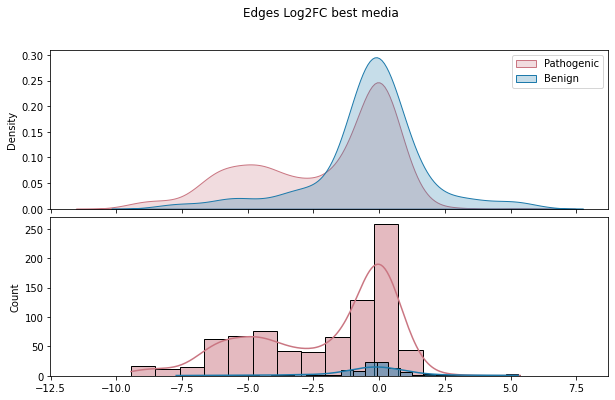

In [517]:
plot_patho_benign(scores=df, metric="log2fc", title="Edges Log2FC best media")

## AUROC AUPRC

In [518]:
def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, 
                                       verbose=False, show_plots=True, balance_dataset=False,
                                       clinvar_col='clinvar_clnsig_clean'):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the dataset to have equal benign and pathogenic counts (50/50 priors)
    clinvar_col : str
        Column to use for ClinVar classification ('clinvar_clnsig_clean' or 'clinvar_clnsig_clean_pp_strict')
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Define pathogenic and benign categories based on clinvar column
    if clinvar_col == "clinvar_clnsig_clean_pp_strict":
        pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
        benign_categories = ['Benign', 'Likely benign']
    else:
        pathogenic_categories = ['Pathogenic']
        benign_categories = ['Benign']
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic (including likely variants if using pp_strict)
    all_categories = pathogenic_categories + benign_categories
    filtered = scores_pd[scores_pd[clinvar_col].isin(all_categories)].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Balance dataset if requested
    if balance_dataset:
        n_pathogenic = filtered[clinvar_col].isin(pathogenic_categories).sum()
        n_benign = filtered[clinvar_col].isin(benign_categories).sum()
        
        if n_pathogenic > n_benign:
            # Oversample benign to match pathogenic
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat benign samples to match pathogenic count
            n_repeats = n_pathogenic // n_benign
            n_remainder = n_pathogenic % n_benign
            
            balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                       [benign_samples.sample(n=n_remainder, random_state=42)], 
                                       ignore_index=True)
            filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
            
        elif n_benign > n_pathogenic:
            # Oversample pathogenic to match benign
            benign_samples = filtered[filtered[clinvar_col].isin(benign_categories)]
            pathogenic_samples = filtered[filtered[clinvar_col].isin(pathogenic_categories)]
            
            # Repeat pathogenic samples to match benign count
            n_repeats = n_benign // n_pathogenic
            n_remainder = n_benign % n_pathogenic
            
            balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                           [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
            filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        if verbose:
            n_path_final = filtered[clinvar_col].isin(pathogenic_categories).sum()
            n_ben_final = filtered[clinvar_col].isin(benign_categories).sum()
            print(f"Dataset balanced: {n_path_final} pathogenic, {n_ben_final} benign")
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = filtered[clinvar_col].isin(pathogenic_categories).astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    if metric_col == "log2fc":
        y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    else:
        y_scores_roc = y_scores  # Adjust as needed for other metrics
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    if show_plots:    
        # Create plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ROC Curve
        axes[0].plot(fpr, tpr, color='royalblue', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc:.3f})')
        axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel('False Positive Rate')
        axes[0].set_ylabel('True Positive Rate')
        axes[0].set_title('ROC Curve')
        axes[0].legend(loc="lower right")
        axes[0].grid(alpha=0.3)
        
        # Precision-Recall Curve
        axes[1].plot(recall, precision, color='royalblue', lw=2,
                    label=f'PR curve (AP = {auprc:.3f})')
        axes[1].axhline(y=y_true.mean(), color='grey', linestyle='--', lw=2,
                        label=f'Random (prevalence = {y_true.mean():.3f})')
        axes[1].set_xlim([0.0, 1.0])
        # axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (PPV)')
        axes[1].set_title('Precision-Recall Curve')
        axes[1].legend(loc="lower left")
        axes[1].grid(alpha=0.3)
        
        if title:
            fig.suptitle(title, fontsize=14, y=1.02)
        
        plt.tight_layout()
        plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    if verbose:
        print(f"\n{'='*60}")
        print(f"Classification Performance: {title if title else metric_col}")
        print(f"{'='*60}")
        print(f"Dataset: {len(filtered)} variants ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
        if clinvar_col == "clinvar_clnsig_clean_pp_strict":
            print(f"  (Including Likely pathogenic and Likely benign)")
        print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
        print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
        print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
        print(f"\nPerformance at Optimal Threshold:")
        print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
        print(f"  Specificity:           {specificity:.4f}")
        print(f"  Precision (PPV):       {ppv:.4f}")
        print(f"  Negative Pred. Value:  {npv:.4f}")
        print(f"  Accuracy:              {accuracy:.4f}")
        print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds,
        'clinvar_col': clinvar_col
    }

Dataset balanced: 832 pathogenic, 832 benign


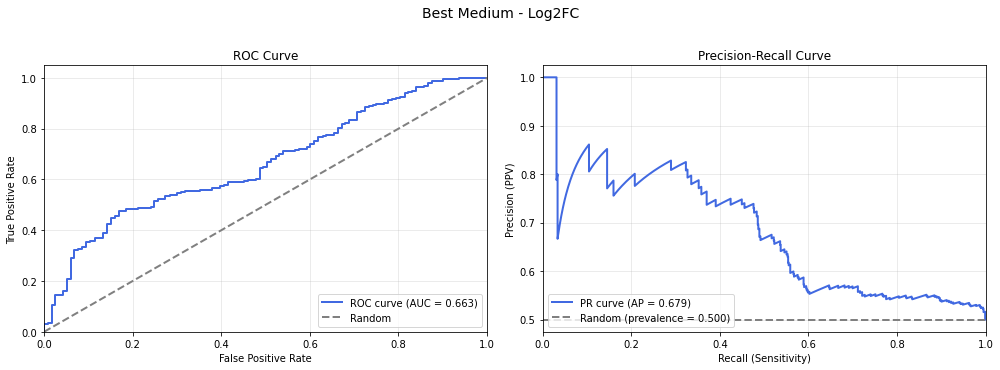


Classification Performance: Best Medium - Log2FC
Dataset: 1664 variants (832 pathogenic, 832 benign)
  (Including Likely pathogenic and Likely benign)

Area Under ROC Curve (AUROC): 0.6627
Area Under PR Curve (AUPRC):  0.6790

Optimal Threshold (Youden): -1.1623

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4760
  Specificity:           0.8317
  Precision (PPV):       0.7388
  Negative Pred. Value:  0.6135
  Accuracy:              0.6538



In [519]:
perf = evaluate_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    title='Best Medium - Log2FC',
    verbose=True,
    balance_dataset=True,
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

## Orf distances

In [520]:
def compute_orf_distances(df):
    
    # normalize consensus score based on max score
    
    consensus_max = df.select(pl.col("consensus_score").max()).item()
    
    df = df.with_columns(
        (pl.col("consensus_score") / consensus_max).alias("consensus_score_normalized"),
        (pl.col("wt_consensus_score") / consensus_max).alias("wt_consensus_score_normalized"),
    )
    
    # Create profiles for each profiled gene
    
    genes = df.select("db_orf_id").to_series().unique().to_list()
    profiles = dict()
    shape_summary = []
    
    for gene in genes:
        gene_scores = df.filter(pl.col("db_orf_id") == gene)
        profile = gene_scores.pivot(
                    values="consensus_score_normalized",
                    index="ad_orf_id",
                    on="db_mut_id"
                )
        
        profiles[gene] = profile

        shape_summary.append({
            "gene": gene,
            "n_interactors": profile.height,
            "n_alleles": profile.width
        })

    shape_summary = pl.DataFrame(shape_summary)
        
    zero_col = "0"

    orf_distances = []


    for orf, profile in profiles.items():
            
        columns = [col for col in profile.columns if col != "ad_orf_id"]

        # "impute" missing values as the mean for that variant
        profile_filled = profile.with_columns([
            pl.when(pl.col(col).is_null())
            .then(pl.col(col).mean())
            .otherwise(pl.col(col))
            .alias(col)
            for col in columns
        ])
        
        # compute distances
        distance_rows = []
        for col in columns:
            if col == zero_col:
                continue
            
            # Euclidean distance
            diff_squared = (profile_filled[col] - profile_filled[zero_col]) ** 2
            distances = np.sqrt(diff_squared.sum())
            

            distance_rows.append({
                "db_orf_id": orf,
                "db_mut_id": int(col),
                "euclid_distance": distances,
                "num_edges": profile.shape[0],
            })


        result_profile = pl.DataFrame(distance_rows)
        orf_distances.append(result_profile)

    # concatentate and normalize wrt dimensionality
    orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
    orf_distances = orf_distances.with_columns(
        (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
        pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
        pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    )

    orf_distances = orf_distances.with_columns(
        (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
    )
    
    orf_distances = metadata_mapping(orf_distances, inputs_dir=inputs_dir, map_ad_symbol=False)
    
    orf_distances = orf_distances.unique(subset=["db_orf_id", "db_mut_id"])
    
    # cast db_orf_id and db_mut_id back to Int64
    orf_distances = orf_distances.with_columns(
        pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
        pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    )
    
    # Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
    orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["gene_variant"], keep="first")
    
    return orf_distances, profiles

In [521]:
orf_distances, profiles = compute_orf_distances(df)
orf_distances

db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,seq,seq_aa,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,…,g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
i64,i64,f64,i64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool
70497,3780,0.485963,1,0.485963,0.525468,"""AGXT""","""ENSG00000172482""","""CCSBVarC008156""","""ALE00008142""","""NC_000002.12:240868893:C:G""","""28C>G""","""Pro10Ala""","""ATGGCCTCTCACAAGCTGCTGGTGACCGCC…","""MASHKLLVTAPKALLKPLSIPNQLLLGPGP…","""Edgotyping3""","""VUSMutGDEh003""","""B11""","""GDEhDisVCh_40002""","""C01""",2.0,"""VUSMutGDDh003""","""B11""","""VUSN2Hmut_GDN2h_01""","""D05""","""VUSMutpDEST2_13""","""D12""","""VUSmut_GDEh01""","""D05""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,-50.7,null,null,null,125.8,null,null,null,null,null,"""H (helix)""","""P (polyproline helix)""",null,null,null,null,null,null,null,null,null,null,null,97.9,70.588234,""">90""","""10-90""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false
5585,215438,0.179828,1,0.179828,0.194446,"""CRYAB""","""ENSG00000109846""","""CCSBVarC006123""","""ALE00006123""","""NC_000011.10:111908822:C:T""","""470G>A""","""Arg157His""","""ATGGACATCGCCATCCACCACCCCTGGATC…","""MDIAIHHPWIRRPFFPFHSPSRLFDQFFGE…","""CEGS2""","""CegsMutGDEh1033""","""F10""","""GDEhDisVCh_40077""","""B05""",1.0,"""CegsMutGDDh1033""","""F10""","""VUSN2Hmut_GDN2h_06""","""A06""","""VUSMutpDEST2_05""","""C03""","""VUSmut_GDEh06""","""A06""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,-114.8,null,null,null,114.9,"""Disordered""",null,null,"""dbSNP: rs141638421; Variant ty…",null,"""C (loop/coil)""","""C (loop/coil)""","""Beta strand""",null,null,null,null,null,null,null,null,null,null,81.14,85.08065,"""70-90""","""10-90""","""608810;615184;613869;613763;61…","""multiple""","""OMIM""","""Rare genetic cardiac disease; …",2,"""MYOPATHY, MYOFIBRILLAR, 2; CAR…",false
3180,214556,0.525696,9,0.175232,0.189477,"""NAA10""","""ENSG00000102030""","""CCSBVarC005876""","""ALE00005876""","""NC_000023.11:153932111:G:A""","""346C>T""","""Arg116Trp""","""ATGAACATCCGCAATGCGAGGCCAGAGGAC…","""MNIRNARPEDLMNMQHCNLLCLPENYQMKY…","""CEGS2""","""CegsMutGDEh1032""","""B06""","""GDEhDisVCh_40035""","""E12""",1.0,"""CegsMutGDDh1032""","""B06""","""VUSN2Hmut_GDN2h_05""","""E12""","""VUSMutpDEST2_03""","""H04""","""VUSmut_GDEh05""","""E12""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,-55.9,null,null,null,-34.1,null,null,null,null,null,"""H (hel

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 489
Total unique db_orf_id: 73
Total Pathogenic variants: 242
Total Benign variants: 31


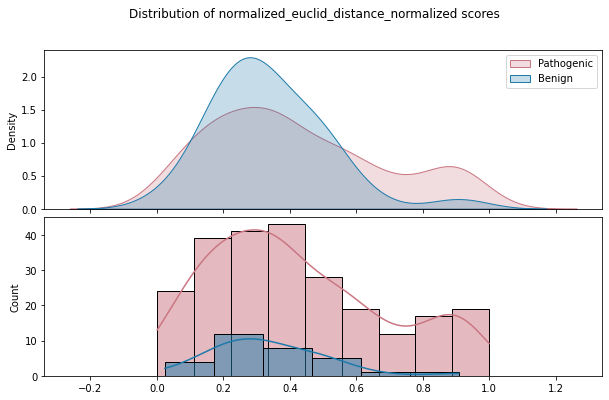

In [522]:
plot_patho_benign(scores=orf_distances)#, threshold=LLR_threshold)

# Run full pipeline to get final scores

In [523]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

def run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions, use_median=False):
    """
    Run the complete sqY2H analysis pipeline.
    
    Parameters:
    -----------
    min_growth_score : int
        Minimum growth score threshold for filtering
    scoring_conditions : list
        List of scoring conditions to use for best media selection
        
    Returns:
    --------
    tuple : (df, orf_distances, perf, tracking_dict)
        - df: Polars DataFrame with filtered edge-level scores
        - orf_distances: Polars DataFrame with variant-level distance metrics
        - perf: Dictionary with classification performance metrics
        - tracking_dict: Dictionary tracking data at each pipeline step
    """
    # Initialize tracking
    tracking_dict = {}
    
    # Load original dataframe
    df, tracking_dict = load_original_dataframe(
        file_path=original_datafile_path,
        tracking_dict=tracking_dict
    )
    
    # Initial QA/QC
    df, tracking_dict = initial_qaqc(df, tracking_dict=tracking_dict)
    
    # Calculate consensus scores
    df, tracking_dict = consensus_score_calculation(df, tracking_dict=tracking_dict, use_median=use_median)
    
    # Map metadata
    df = metadata_mapping(df, meta_output=meta_output, inputs_dir=inputs_dir)
    
    # Remove splicing variants
    df = remove_splicing_variants(df)
    
    
    # Sequencing filtering
    df, tracking_dict = sequencing_filtering(
        df,
        tracking_dict=tracking_dict,
        meta_output=meta_output,
        inputs_dir=inputs_dir
    )
    
    # QA/QC filtering
    df, tracking_dict = qa_qc_filtering(
        df,
        tracking_dict=tracking_dict,
        min_growth_score=min_growth_score
    )
    
    # Select best media
    df, tracking_dict = select_best_media(
        df,
        scoring_conditions=scoring_conditions,
        min_growth_score=min_growth_score,
        verbose=True,
        tracking_dict=tracking_dict
    )
    
    # Evaluate classification performance
    perf = evaluate_classification_performance(
        df.filter(pl.col("db_mut_id") != 0),
        metric_col='log2fc',
        title='PPIs - Log2FC',
        verbose=True,
        balance_dataset=True
    )
    
    # Compute ORF distances
    orf_distances, profiles = compute_orf_distances(df)
    
    # Plot distribution
    plot_patho_benign(
        scores=orf_distances,
        metric="normalized_euclid_distance_normalized",
        title="ORF Distances - Normalized Euclidean Distance"
    )
    
    # Evaluate classification performance
    perf = evaluate_classification_performance(
        orf_distances.filter(pl.col("db_mut_id") != 0),
        metric_col='normalized_euclid_distance_normalized',
        title='ORF Distances - Normalized Euclidean Distance',
        verbose=True,
        balance_dataset=True
    )
    
    return df, orf_distances, perf, tracking_dict

## No LWA

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Total edges with benign variants: 73
Total edges with WT fallback: 755
Total edges covered: 835
Filtered scores shape: (2704, 1044)
Total unique ppis before filtering: 2578
Valid ppis after filtering: 1998
Dataset balanced: 832 pathogenic, 832 benign


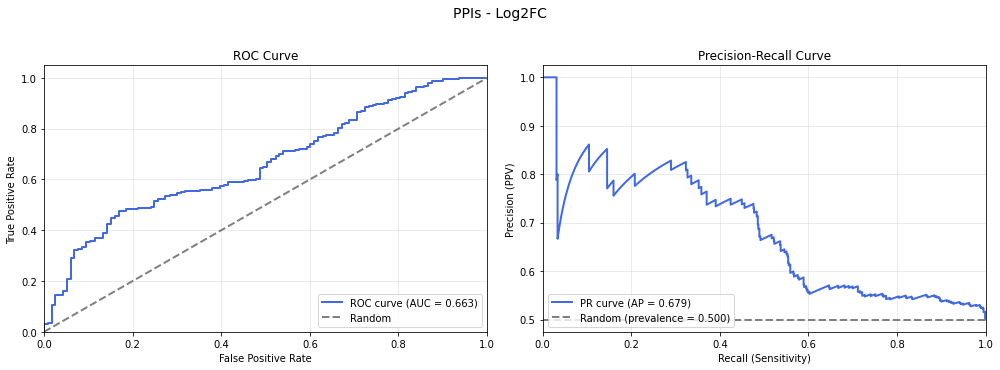


Classification Performance: PPIs - Log2FC
Dataset: 1664 variants (832 pathogenic, 832 benign)

Area Under ROC Curve (AUROC): 0.6627
Area Under PR Curve (AUPRC):  0.6790

Optimal Threshold (Youden): -1.1623

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4760
  Specificity:           0.8317
  Precision (PPV):       0.7388
  Negative Pred. Value:  0.6135
  Accuracy:              0.6538

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 489
Total unique db_orf_id: 73
Total Pathogenic variants: 242
Total Benign variants: 31


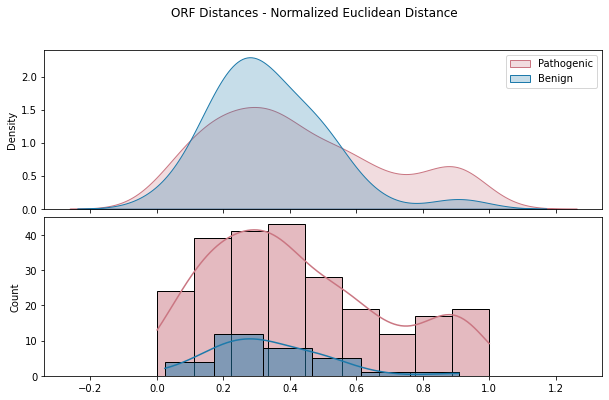

Dataset balanced: 242 pathogenic, 242 benign


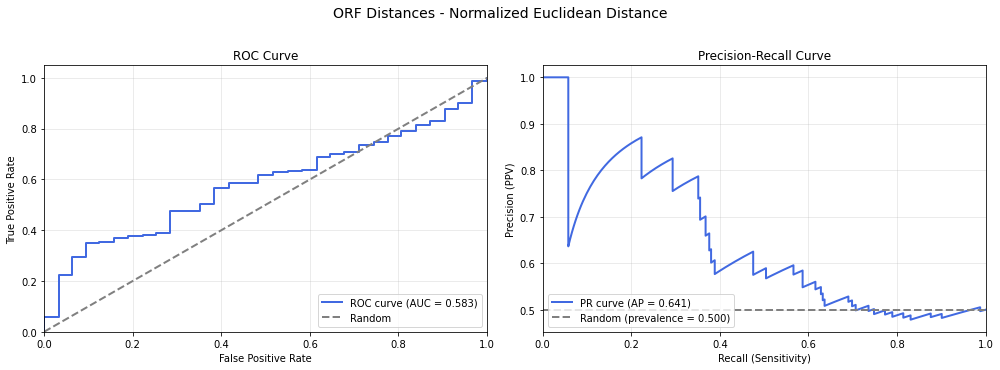


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 484 variants (242 pathogenic, 242 benign)

Area Under ROC Curve (AUROC): 0.5831
Area Under PR Curve (AUPRC):  0.6412

Optimal Threshold (Youden): -0.5040

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.3512
  Specificity:           0.9050
  Precision (PPV):       0.7870
  Negative Pred. Value:  0.5824
  Accuracy:              0.6281



In [524]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25']

df, orf_distances, perf, tracking_dict = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions, use_median=True)

## tables for Leo

In [525]:
df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
).select(['symbol', 'aa_change', 'db_mut_id', 'ad_symbol','clinvar_clnsig_clean_pp_strict', 'consensus_score', 'wt_consensus_score', 'log2fc']).write_csv(f"{outputs_dir}/ppi_level_scores_minimal_update3.csv")

In [526]:
orf_distances[['symbol', 'aa_change', 'db_mut_id', 'gene_variant' ,'clinvar_clnsig_clean_pp_strict', 'normalized_euclid_distance_normalized']].write_csv(f"{outputs_dir}/orf_distances_minimal3.csv")

In [527]:
print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 1998
Number of unique edge_group: 274
Number of unique db_orf_id: 73
Number of unique db_mut_id: 489


In [528]:
def add_structural_categories(orf_distances):
    """
    Add pLDDT and RSA category columns to orf_distances DataFrame.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing plddt and rsa columns
        
    Returns:
    --------
    pl.DataFrame
        DataFrame with added pLDDT_Category and RSA_Category columns
    """
    
    # Define RSA categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("rsa") < 0.10)
        .then(pl.lit("<10"))
        .when((pl.col("rsa") >= 0.10) & (pl.col("rsa") < 0.90))
        .then(pl.lit("10-90"))
        .when(pl.col("rsa") >= 0.90)
        .then(pl.lit("≥90"))
        .otherwise(None)
        .alias("RSA_Category")
    )
    
    # Define pLDDT categories
    orf_distances = orf_distances.with_columns(
        pl.when(pl.col("plddt") <= 50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt") > 50) & (pl.col("plddt") <= 70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt") > 70) & (pl.col("plddt") <= 90))
        .then(pl.lit("70-90"))
        .when(pl.col("plddt") > 90)
        .then(pl.lit(">90"))
        .otherwise(None)
        .alias("pLDDT_Category")
    )
    
    return orf_distances

In [529]:
# Add categories to orf_distances
orf_distances = add_structural_categories(orf_distances)

# Check the result
print(orf_distances.select(['plddt', 'pLDDT_Category', 'rsa', 'RSA_Category']).head())

# Check distribution
print("\nRSA Category counts:")
print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))

print("\npLDDT Category counts:")
print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))

shape: (5, 4)
┌───────┬────────────────┬──────────┬──────────────┐
│ plddt ┆ pLDDT_Category ┆ rsa      ┆ RSA_Category │
│ ---   ┆ ---            ┆ ---      ┆ ---          │
│ f64   ┆ str            ┆ f64      ┆ str          │
╞═══════╪════════════════╪══════════╪══════════════╡
│ 98.72 ┆ >90            ┆ 0.0      ┆ <10          │
│ 87.33 ┆ 70-90          ┆ 0.083333 ┆ <10          │
│ 97.63 ┆ >90            ┆ 0.129032 ┆ 10-90        │
│ 97.95 ┆ >90            ┆ 0.451087 ┆ 10-90        │
│ 81.22 ┆ 70-90          ┆ 0.59009  ┆ 10-90        │
└───────┴────────────────┴──────────┴──────────────┘

RSA Category counts:
shape: (4, 2)
┌──────────────┬───────┐
│ RSA_Category ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ null         ┆ 7     │
│ 10-90        ┆ 303   │
│ <10          ┆ 157   │
│ ≥90          ┆ 22    │
└──────────────┴───────┘

pLDDT Category counts:
shape: (5, 2)
┌────────────────┬───────┐
│ pLDDT_Category ┆ count │
│ ---            ┆ ---   

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3766873533.py:9: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('RSA_Category').agg(pl.count()).sort('RSA_Category'))
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3766873533.py:12: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(orf_distances.group_by('pLDDT_Category').agg(pl.count()).sort('pLDDT_Category'))


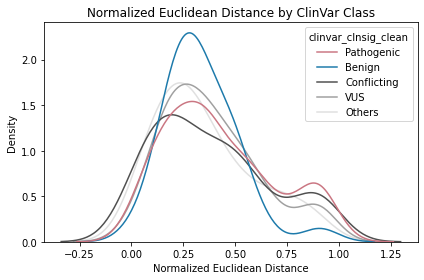

In [530]:
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)


plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1887552775.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


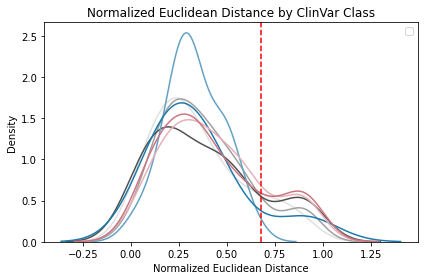

In [314]:

hue_order = ["Pathogenic", 'Likely pathogenic', "Benign", 'Likely benign', "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean_pp_strict",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean_pp_strict'],
    common_norm=False
)

# plt.axvline(x=LLR_threshold, color='red', linestyle='--', label='Threshold')

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.axvline(x=0.678, color='red', linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

## LWA

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Total edges with benign variants: 89
Total edges with WT fallback: 792
Total edges covered: 887
Filtered scores shape: (3189, 1044)
Total unique ppis before filtering: 2821
Valid ppis after filtering: 2234
Dataset balanced: 962 pathogenic, 962 benign


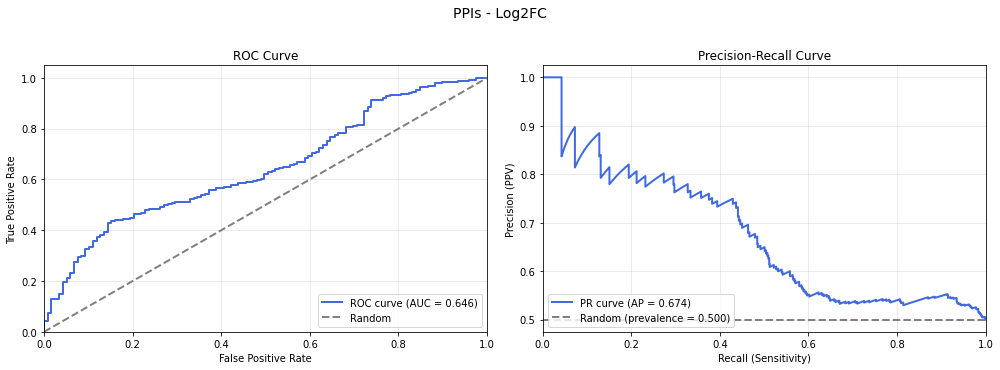


Classification Performance: PPIs - Log2FC
Dataset: 1924 variants (962 pathogenic, 962 benign)

Area Under ROC Curve (AUROC): 0.6456
Area Under PR Curve (AUPRC):  0.6741

Optimal Threshold (Youden): -1.1961

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4293
  Specificity:           0.8565
  Precision (PPV):       0.7495
  Negative Pred. Value:  0.6001
  Accuracy:              0.6429

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 504
Total unique db_orf_id: 75
Total Pathogenic variants: 258
Total Benign variants: 31


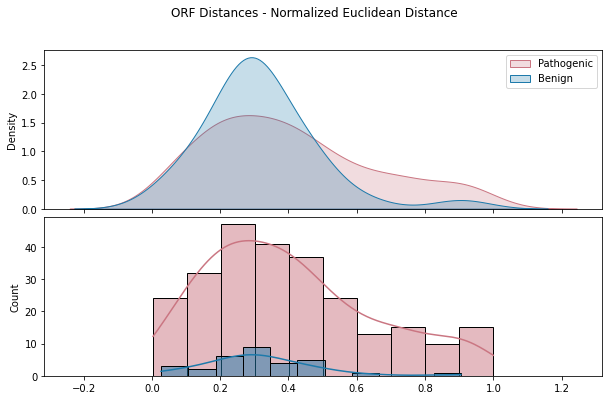

Dataset balanced: 258 pathogenic, 258 benign


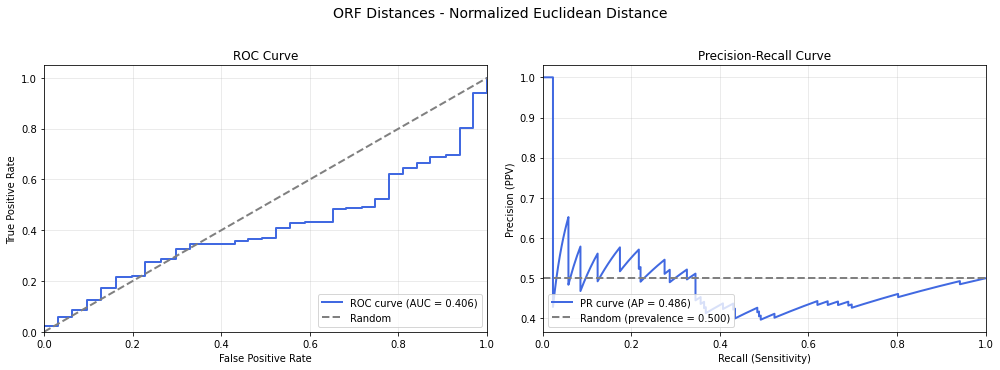


Classification Performance: ORF Distances - Normalized Euclidean Distance
Dataset: 516 variants (258 pathogenic, 258 benign)

Area Under ROC Curve (AUROC): 0.4058
Area Under PR Curve (AUPRC):  0.4861

Optimal Threshold (Youden): 0.2025

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.2171
  Specificity:           0.8372
  Precision (PPV):       0.5714
  Negative Pred. Value:  0.5167
  Accuracy:              0.5271



In [148]:
min_growth_score = 200
scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']

df_lwa, orf_distances_lwa, perf_lwa, tracking_dict_lwa = run_full_pipeline(min_growth_score=min_growth_score, scoring_conditions=scoring_conditions)

In [149]:
# number of ppi_group, edge_group, db_orf_id, db_mut_id in df_lwa

print("Final filtered dataframe stats:")
print("Number of unique ppi_group:", df_lwa.select(pl.col("ppi_group").n_unique()).item())
print("Number of unique edge_group:", df_lwa.select(pl.col("edge_group").n_unique()).item())
print("Number of unique db_orf_id:", df_lwa.select(pl.col("db_orf_id").n_unique()).item())
print("Number of unique db_mut_id:", df_lwa.select(pl.col("gene_variant").n_unique()).item() - 1)

Final filtered dataframe stats:
Number of unique ppi_group: 2234
Number of unique edge_group: 317
Number of unique db_orf_id: 75
Number of unique db_mut_id: 504


## AUROC comparison between LWA and non-LWA

In [150]:
def compare_classification_performance(scores_df1, scores_df2, metric_col, 
                                      label1='Dataset 1', label2='Dataset 2',
                                      title=None, filter_edges=None, 
                                      verbose=False, balance_dataset=False):
    """
    Compare classification performance between two datasets on the same ROC and PR plots.
    
    Parameters:
    -----------
    scores_df1 : polars.DataFrame
        First DataFrame containing scores and clinical significance
    scores_df2 : polars.DataFrame
        Second DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    label1 : str
        Label for first dataset
    label2 : str
        Label for second dataset
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    balance_dataset : bool, optional
        If True, balance the datasets to have equal benign and pathogenic counts
    
    Returns:
    --------
    dict : Dictionary containing metrics for both datasets
    """
    
    def prepare_data(scores_df, balance=False):
        """Helper function to prepare data for each dataset"""
        scores_pd = scores_df.to_pandas()
        
        # Filter by number of edges if specified
        if filter_edges is not None and 'num_edges' in scores_pd.columns:
            scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
        
        # Filter to only benign and pathogenic
        filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['Pathogenic', 'Benign'])].copy()
        
        # Remove NaN values in metric column
        filtered = filtered[filtered[metric_col].notna()]
        
        if len(filtered) < 10:
            print(f"Warning: Only {len(filtered)} variants available")
            return None, None, None
        
        # Balance dataset if requested
        if balance:
            n_pathogenic = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').sum()
            n_benign = (filtered['clinvar_clnsig_clean'] == 'Benign').sum()
            
            if n_pathogenic > n_benign:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_pathogenic // n_benign
                n_remainder = n_pathogenic % n_benign
                
                balanced_benign = pd.concat([benign_samples] * n_repeats + 
                                           [benign_samples.sample(n=n_remainder, random_state=42)], 
                                           ignore_index=True)
                filtered = pd.concat([pathogenic_samples, balanced_benign], ignore_index=True)
                
            elif n_benign > n_pathogenic:
                benign_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Benign']
                pathogenic_samples = filtered[filtered['clinvar_clnsig_clean'] == 'Pathogenic']
                
                n_repeats = n_benign // n_pathogenic
                n_remainder = n_benign % n_pathogenic
                
                balanced_pathogenic = pd.concat([pathogenic_samples] * n_repeats + 
                                               [pathogenic_samples.sample(n=n_remainder, random_state=42)], 
                                               ignore_index=True)
                filtered = pd.concat([benign_samples, balanced_pathogenic], ignore_index=True)
        
        # Create binary labels (1 = Pathogenic, 0 = Benign)
        y_true = (filtered['clinvar_clnsig_clean'] == 'Pathogenic').astype(int)
        y_scores = filtered[metric_col].values
        
        # For log2fc, more negative = more pathogenic, so we negate for ROC
        y_scores_roc = -y_scores
        
        return y_true, y_scores_roc, filtered
    
    # Prepare data for both datasets
    y_true1, y_scores1, filtered1 = prepare_data(scores_df1, balance=balance_dataset)
    y_true2, y_scores2, filtered2 = prepare_data(scores_df2, balance=balance_dataset)
    
    if y_true1 is None or y_true2 is None:
        return None
    
    # Calculate metrics for both datasets
    fpr1, tpr1, roc_thresholds1 = roc_curve(y_true1, y_scores1)
    roc_auc1 = auc(fpr1, tpr1)
    precision1, recall1, pr_thresholds1 = precision_recall_curve(y_true1, y_scores1)
    auprc1 = average_precision_score(y_true1, y_scores1)
    
    fpr2, tpr2, roc_thresholds2 = roc_curve(y_true2, y_scores2)
    roc_auc2 = auc(fpr2, tpr2)
    precision2, recall2, pr_thresholds2 = precision_recall_curve(y_true2, y_scores2)
    auprc2 = average_precision_score(y_true2, y_scores2)
    
    # Create comparison plots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # ROC Curve
    axes[0].plot(fpr1, tpr1, color='royalblue', lw=2, 
                label=f'{label1} (AUC = {roc_auc1:.3f})')
    axes[0].plot(fpr2, tpr2, color='coral', lw=2, 
                label=f'{label2} (AUC = {roc_auc2:.3f})')
    axes[0].plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--', label='Random')
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC Curve Comparison')
    axes[0].legend(loc="lower right")
    axes[0].grid(alpha=0.3)
    
    # Precision-Recall Curve
    axes[1].plot(recall1, precision1, color='royalblue', lw=2,
                label=f'{label1} (AP = {auprc1:.3f})')
    axes[1].plot(recall2, precision2, color='coral', lw=2,
                label=f'{label2} (AP = {auprc2:.3f})')
    axes[1].axhline(y=y_true1.mean(), color='grey', linestyle='--', lw=2,
                    label=f'Random (prevalence = {y_true1.mean():.3f})')
    axes[1].set_xlim([0.0, 1.0])
    axes[1].set_xlabel('Recall (Sensitivity)')
    axes[1].set_ylabel('Precision (PPV)')
    axes[1].set_title('Precision-Recall Curve Comparison')
    axes[1].legend(loc="lower left")
    axes[1].grid(alpha=0.3)
    
    if title:
        fig.suptitle(title, fontsize=14, y=1.02)
    
    plt.tight_layout()
    plt.show()
    
    # Print comparison summary
    if verbose:
        print(f"\n{'='*80}")
        print(f"Classification Performance Comparison: {title if title else metric_col}")
        print(f"{'='*80}")
        print(f"\n{label1}:")
        print(f"  Dataset: {len(filtered1)} variants ({y_true1.sum()} pathogenic, {len(y_true1) - y_true1.sum()} benign)")
        print(f"  AUROC: {roc_auc1:.4f}")
        print(f"  AUPRC: {auprc1:.4f}")
        
        print(f"\n{label2}:")
        print(f"  Dataset: {len(filtered2)} variants ({y_true2.sum()} pathogenic, {len(y_true2) - y_true2.sum()} benign)")
        print(f"  AUROC: {roc_auc2:.4f}")
        print(f"  AUPRC: {auprc2:.4f}")
        
        print(f"\nDifference:")
        print(f"  ΔAUROC: {roc_auc2 - roc_auc1:+.4f}")
        print(f"  ΔAUPRC: {auprc2 - auprc1:+.4f}")
        print(f"{'='*80}\n")
    
    # Return metrics for both datasets
    return {
        'dataset1': {
            'label': label1,
            'auroc': roc_auc1,
            'auprc': auprc1,
            'n_variants': len(filtered1),
            'n_pathogenic': y_true1.sum(),
            'n_benign': len(y_true1) - y_true1.sum(),
            'fpr': fpr1,
            'tpr': tpr1,
            'precision': precision1,
            'recall': recall1
        },
        'dataset2': {
            'label': label2,
            'auroc': roc_auc2,
            'auprc': auprc2,
            'n_variants': len(filtered2),
            'n_pathogenic': y_true2.sum(),
            'n_benign': len(y_true2) - y_true2.sum(),
            'fpr': fpr2,
            'tpr': tpr2,
            'precision': precision2,
            'recall': recall2
        }
    }

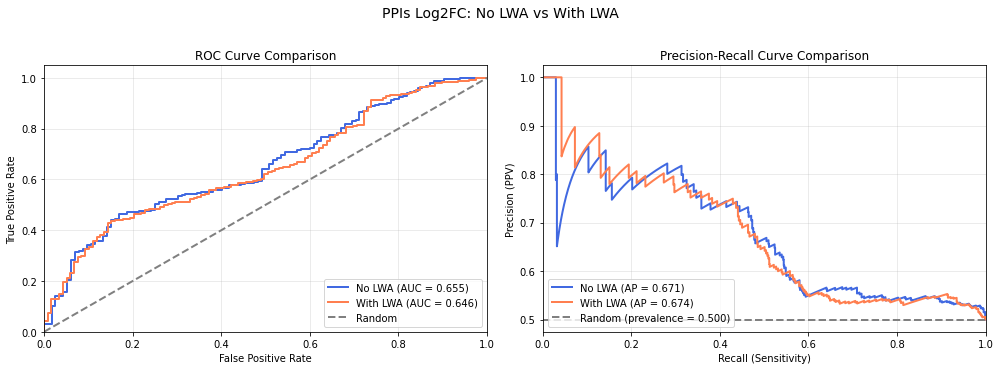


Classification Performance Comparison: PPIs Log2FC: No LWA vs With LWA

No LWA:
  Dataset: 1742 variants (871 pathogenic, 871 benign)
  AUROC: 0.6547
  AUPRC: 0.6712

With LWA:
  Dataset: 1924 variants (962 pathogenic, 962 benign)
  AUROC: 0.6456
  AUPRC: 0.6741

Difference:
  ΔAUROC: -0.0091
  ΔAUPRC: +0.0029



In [151]:
# Compare df and df_lwa
comparison = compare_classification_performance(
    df.filter(pl.col("db_mut_id") != 0),
    df_lwa.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc',
    label1='No LWA',
    label2='With LWA',
    title='PPIs Log2FC: No LWA vs With LWA',
    verbose=True,
    balance_dataset=True
)

In [152]:
# LWA doesn't seem to make a big difference in performance and is quite different from the other 3AT media, so we will proceed with the dataset without LWA for further analyses.

In [153]:
stop

NameError: name 'stop' is not defined

# LLR

In [531]:
orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.value_counts()

clinvar_clnsig_clean_pp_strict
Pathogenic           153
Likely pathogenic     89
VUS                   87
Conflicting           78
Others                51
Likely benign         23
Benign                 8
Name: count, dtype: int64

In [532]:
orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv")

orf_distances.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv")

In [533]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-24_13:53:29 INFO: Reading input 
2025-11-24_13:53:29 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-24_13:53:30 INFO: Drawing LLR plot 
2025-11-24_13:53:30 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-24_13:53:30 INFO: Category transitions:  
0.675 : none -> patho.support
0.757 : patho.support -> patho.moderate
0.938 : patho.moderate -> patho.support
2025-11-24_13:53:30 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-24_13:53:30 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_bcv.csv 
2025-11-24_13:53:30 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-24_13:53:34 INFO: Drawing LLR plot 
2025-11-24_13:53:34 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-24_13:53:34 INFO: Category transitions:  
0.693 : none -> patho.support
0.837 : patho.support -> patho.moderate
0.959 : patho.moderate -> patho.support
0.995 : patho.support -> none
2025-11-24_13:53:34 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-24_13:53:34 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_default.csv 
2025-11-24_13:53:34 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-24_13:53:35 INFO: Reading input 
2025-11-24_13:53:35 INFO: Calculating densties 
2025-11-24_13:53:36 INFO: Drawing LLR plot 
2025-11-24_13:53:36 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-24_13:53:36 INFO: Category transitions:  
0.667 : none -> patho.support
0.740 : patho.support -> patho.moderate
0.908 : patho.moderate -> patho.support
2025-11-24_13:53:36 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-24_13:53:36 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_nrd.csv 
2025-11-24_13:53:36 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-24_13:53:37 INFO: Reading input 
2025-11-24_13:53:37 INFO: Calculating densties 
2025-11-24_13:53:38 INFO: Drawing LLR plot 
2025-11-24_13:53:38 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-24_13:53:38 INFO: Category transitions:  
0.665 : none -> patho.support
0.740 : patho.support -> patho.moderate
0.960 : patho.moderate -> patho.support
2025-11-24_13:53:38 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-24_13:53:38 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_LLR_score_sj.csv 
2025-11-24_13:53:38 INFO: Done! 


In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

# Define parameter arrays
KERNELS=("gaussian" "epanechnikov" "rectangular" "triangular" "biweight" "cosine")
OUTLIER_SUPPRESSIONS=(0 0.05 0.1 0.15 0.2 0.25 0.30 0.35 0.4 0.45 0.5 0.55 0.6 0.65 0.7 0.75 0.8 0.85 0.9 0.95 1)
BANDWIDTHS=("bcv" "nrd0" "nrd" "SJ")

# Loop through all combinations
for kernel in "${KERNELS[@]}"; do
    for outlier in "${OUTLIER_SUPPRESSIONS[@]}"; do
        for bandwidth in "${BANDWIDTHS[@]}"; do
            # Create meaningful output names
            output_suffix="${kernel}_${bandwidth}_outlier${outlier}"
            
            echo "Running with kernel=${kernel}, bandwidth=${bandwidth}, outlierSuppression=${outlier}"
            
            Rscript ../../threshold_calibration/calcLLR.R \
                ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_allScores.csv \
                ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_referenceSet.csv \
                --outfile "../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_${output_suffix}" \
                --logfile "../3_outputs/sqY2H/calcLLR/output/log/PPI_Best_Media_LLR_${output_suffix}.log" \
                --bandwidth "${bandwidth}" \
                --kernel "${kernel}" \
                --outlierSuppression ${outlier} \
                --printTransitions
        done
    done
done

echo "All parameter combinations completed!"

Running with kernel=gaussian, bandwidth=bcv, outlierSuppression=0


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_11:30:24 INFO: Reading input 
2025-11-17_11:30:24 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-17_11:30:25 INFO: Drawing LLR plot 
2025-11-17_11:30:25 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_11:30:25 INFO: Category transitions:  
0.678 : none -> patho.support
0.762 : patho.support -> patho.moderate
0.928 : patho.moderate -> patho.support
2025-11-17_11:30:25 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_11:30:25 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_gaussian_bcv_outlier0.csv 
2025-11-17_11:30:25 INFO: Done! 
Running with kernel=gaussian, bandwidth=nrd0, outlierSuppression=0


...

2025-11-17_11:45:33 INFO: Reading input 
2025-11-17_11:45:33 INFO: Calculating densties 
2025-11-17_11:45:34 INFO: Drawing LLR plot 
2025-11-17_11:45:34 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_11:45:35 INFO: Category transitions:  
0.654 : none -> patho.support
0.834 : patho.support -> patho.moderate
0.897 : patho.moderate -> patho.support
2025-11-17_11:45:35 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_11:45:35 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_cosine_nrd0_outlier1.csv 
2025-11-17_11:45:35 INFO: Done! 
Running with kernel=cosine, bandwidth=nrd, outlierSuppression=1


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_11:45:35 INFO: Reading input 
2025-11-17_11:45:35 INFO: Calculating densties 
2025-11-17_11:45:36 INFO: Drawing LLR plot 
2025-11-17_11:45:36 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_11:45:37 INFO: Category transitions:  
0.672 : none -> patho.support
0.739 : patho.support -> patho.moderate
0.923 : patho.moderate -> patho.support
2025-11-17_11:45:37 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_11:45:37 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_cosine_nrd_outlier1.csv 
2025-11-17_11:45:37 INFO: Done! 
Running with kernel=cosine, bandwidth=SJ, outlierSuppression=1


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_11:45:37 INFO: Reading input 
2025-11-17_11:45:37 INFO: Calculating densties 
2025-11-17_11:45:38 INFO: Drawing LLR plot 
2025-11-17_11:45:38 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_11:45:39 INFO: Category transitions:  
0.669 : none -> patho.support
0.827 : patho.support -> patho.moderate
0.951 : patho.moderate -> patho.support
0.998 : patho.support -> none
2025-11-17_11:45:39 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_11:45:39 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/figs/PPI_Best_Media_LLR_cosine_SJ_outlier1.csv 
2025-11-17_11:45:39 INFO: Done! 
All parameter combinations completed!


In [ ]:
import os
import shutil
from pathlib import Path

# Define paths
output_base = "../3_outputs/sqY2H/calcLLR/output/figs"
organized_base = "../3_outputs/sqY2H/calcLLR/output/organized"

# Create organized directory if it doesn't exist
Path(organized_base).mkdir(parents=True, exist_ok=True)

# Get all PDF files, excluding those ending with _prc.pdf
pdf_files = [f for f in Path(output_base).glob("*.pdf") if not f.stem.endswith("_prc")]

print(f"Found {len(pdf_files)} PDF files (excluding _prc.pdf files)")

# Organize files
for pdf_file in pdf_files:
    # Extract parameters from filename
    # Format: PPI_Best_Media_LLR_{kernel}_{bandwidth}_outlier{value}.pdf
    filename = pdf_file.stem  # Remove .pdf extension
    
    # Remove prefix
    if filename.startswith("PPI_Best_Media_LLR_"):
        params = filename.replace("PPI_Best_Media_LLR_", "")
        
        # Split into kernel, bandwidth, and outlier
        parts = params.split("_")
        
        if len(parts) >= 3:
            kernel = parts[0]
            bandwidth = parts[1]
            outlier = "_".join(parts[2:])  # In case outlier value has underscores
            
            # Create folder structure: organized/{kernel}/{bandwidth}/
            folder_path = Path(organized_base) / kernel / bandwidth
            folder_path.mkdir(parents=True, exist_ok=True)
            
            # Copy file to organized location
            dest_path = folder_path / pdf_file.name
            shutil.copy2(pdf_file, dest_path)
            
            print(f"Copied {pdf_file.name} -> {kernel}/{bandwidth}/")

print(f"\nOrganization complete! Files organized in {organized_base}")

# Print summary
kernels = [d.name for d in Path(organized_base).iterdir() if d.is_dir()]
print(f"\nKernels found: {sorted(kernels)}")

for kernel in sorted(kernels):
    kernel_path = Path(organized_base) / kernel
    bandwidths = [d.name for d in kernel_path.iterdir() if d.is_dir()]
    print(f"\n{kernel}:")
    for bandwidth in sorted(bandwidths):
        n_files = len(list((kernel_path / bandwidth).glob("*.pdf")))
        print(f"  {bandwidth}: {n_files} files")

Found 357 PDF files (excluding _prc.pdf files)
Copied PPI_Best_Media_LLR_biweight_bcv_outlier0.7.pdf -> biweight/bcv/
Copied PPI_Best_Media_LLR_cosine_nrd0_outlier0.15.pdf -> cosine/nrd0/
Copied PPI_Best_Media_LLR_gaussian_nrd0_outlier0.35.pdf -> gaussian/nrd0/
Copied PPI_Best_Media_LLR_triangular_bcv_outlier0.9.pdf -> triangular/bcv/
Copied PPI_Best_Media_LLR_triangular_nrd_outlier0.pdf -> triangular/nrd/
Copied PPI_Best_Media_LLR_epanechnikov_nrd0_outlier0.55.pdf -> epanechnikov/nrd0/
Copied PPI_Best_Media_LLR_gaussian_bcv_outlier0.9.pdf -> gaussian/bcv/
Copied PPI_Best_Media_LLR_epanechnikov_nrd_outlier0.7.pdf -> epanechnikov/nrd/
Copied PPI_Best_Media_LLR_gaussian_SJ_outlier0.55.pdf -> gaussian/SJ/
Copied PPI_Best_Media_LLR_triangular_bcv_outlier0.05.pdf -> triangular/bcv/
Copied PPI_Best_Media_LLR_biweight_nrd0_outlier0.15.pdf -> biweight/nrd0/
Copied PPI_Best_Media_LLR_epanechnikov_nrd_outlier0.6.pdf -> epanechnikov/nrd/
Copied PPI_Best_Media_LLR_cosine_bcv_outlier0.55.pdf -> cos

In [534]:
# Check distribution at low scores
low_score_data = orf_distances.filter(pl.col("normalized_euclid_distance_normalized") < 0.1)
print(low_score_data.group_by("clinvar_clnsig_clean").agg(pl.count()))

shape: (5, 2)
┌──────────────────────┬───────┐
│ clinvar_clnsig_clean ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ VUS                  ┆ 4     │
│ Conflicting          ┆ 11    │
│ Benign               ┆ 1     │
│ Pathogenic           ┆ 23    │
│ Others               ┆ 7     │
└──────────────────────┴───────┘


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/688382294.py:3: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  print(low_score_data.group_by("clinvar_clnsig_clean").agg(pl.count()))


In [535]:
LLR_threshold = 0.675

In [536]:
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("normalized_euclid_distance_normalized") >= LLR_threshold)
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("ppi_hit")
)

In [537]:
orf_distances.write_csv(f"{outputs_dir}/orf_distances_final.csv")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 489
Total unique db_orf_id: 73
Total Pathogenic variants: 242
Total Benign variants: 31
path_thres: 0.9241599048743057
fixed_threshold: 0.678


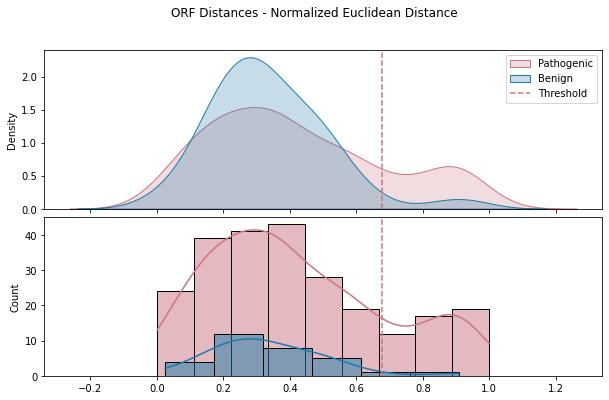

Benign: 1 (3.23%)
Pathogenic: 48 (19.83%)
VUS: 11 (12.64%)
Conflicting: 13 (16.67%)


In [462]:
plot_patho_benign(orf_distances, metric="normalized_euclid_distance_normalized", threshold=True, fixed_threshold=0.6780, title="ORF Distances - Normalized Euclidean Distance")

In [ ]:
df_pd = df.to_pandas()

df_pd[(
    df_pd.symbol == 'STXBP1'
) &
      (df_pd.aa_change.str.contains('His245'))
      ][['aa_change','clinvar_clnsig_clean_pp_strict', 'ad_symbol' ,'log2fc']]

,aa_change,clinvar_clnsig_clean_pp_strict,ad_symbol,log2fc
583,His245Arg,Likely pathogenic,CENPP,-5.377040
840,His245Arg,Likely pathogenic,TRIM38,-3.931318
1919,His245Arg,Likely pathogenic,STX5,-3.681050


In [ ]:
df_pd = df.to_pandas()

df_pd[(
    df_pd.symbol == 'STXBP1'
) &
      (df_pd.aa_change.str.contains('Arg406'))
      ][['aa_change','clinvar_clnsig_clean_pp_strict', 'ad_symbol' ,'log2fc']]

,aa_change,clinvar_clnsig_clean_pp_strict,ad_symbol,log2fc
590,Arg406His,Likely pathogenic,CENPP,-5.029993
782,Arg406His,Likely pathogenic,SYTL4,-3.439792
860,Arg406Leu,Likely pathogenic,TRIM38,-6.249099
891,Arg406His,Likely pathogenic,STX19,-4.990054
1940,Arg406Leu,Likely pathogenic,STX5,-3.640812


In [ ]:
df_pd = df.to_pandas()

df_pd[(
    df_pd.symbol == 'STXBP1'
) &
      (df_pd.aa_change.str.contains('Arg190'))
      ][['aa_change','clinvar_clnsig_clean_pp_strict', 'ad_symbol' ,'log2fc']]

,aa_change,clinvar_clnsig_clean_pp_strict,ad_symbol,log2fc
576,Arg190Gln,Conflicting,CENPP,-4.687753
580,Arg190Trp,Pathogenic,CENPP,-5.031770
775,Arg190Trp,Pathogenic,SYTL4,-9.439702
839,Arg190Gln,Conflicting,TRIM38,-5.983777
881,Arg190Gln,Conflicting,STX19,-6.846388
885,Arg190Trp,Pathogenic,STX19,-1.061301
1918,Arg190Gln,Conflicting,STX5,-4.340951
1929,Arg190Trp,Pathogenic,STX5,-1.329696


## Edge level

Plotting log2fc distribution for Pathogenic and Benign variants
Total variants: 2133
Total unique db_orf_id: 73
Total Pathogenic variants: 899
Total Benign variants: 113


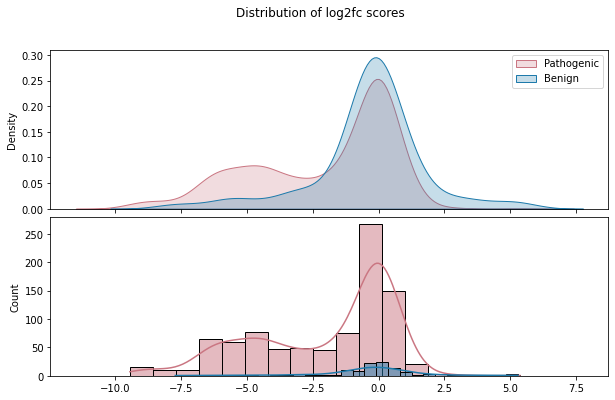

In [ ]:
plot_patho_benign(scores=df, metric="log2fc")

In [ ]:
df.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "log2fc", "ppi_group", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_referenceSet.csv")

df.with_columns(
    pl.col("log2fc").alias("score"),
    pl.col("ppi_group").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_allScores.csv")

In [ ]:
# %%bash
# source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_bcv.log" --bandwidth "bcv" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_default.log" --printTransitions
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_Best_Media_Edges_allScores.csv ../3_outputs/sqY2H/PPI_Best_Media_Edges_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_Best_Media_Edges_LLR_sj.log" --printTransitions --bandwidth "SJ"

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

# Define parameter arrays
KERNELS=("gaussian" "epanechnikov" "rectangular" "triangular" "biweight" "cosine")
OUTLIER_SUPPRESSIONS=(0 0.05 0.1 0.15 0.2 0.25 0.30 0.35 0.4 0.45 0.5 0.55 0.6 0.65 0.7 0.75 0.8 0.85 0.9 0.95 1)
BANDWIDTHS=("bcv" "nrd0" "nrd" "SJ")

# Loop through all combinations
for kernel in "${KERNELS[@]}"; do
    for outlier in "${OUTLIER_SUPPRESSIONS[@]}"; do
        for bandwidth in "${BANDWIDTHS[@]}"; do
            # Create meaningful output names
            output_suffix="${kernel}_${bandwidth}_outlier${outlier}"
            
            echo "Running with kernel=${kernel}, bandwidth=${bandwidth}, outlierSuppression=${outlier}"
            
            Rscript ../../threshold_calibration/calcLLR.R \
                ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_allScores.csv \
                ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_Edges_referenceSet.csv \
                --outfile "../3_outputs/sqY2H/calcLLR/output/edges/figs/PPI_Best_Media_Edges_LLR_${output_suffix}" \
                --logfile "../3_outputs/sqY2H/calcLLR/output/edges/log/PPI_Best_Media_Edges_LLR_${output_suffix}.log" \
                --bandwidth "${bandwidth}" \
                --kernel "${kernel}" \
                --outlierSuppression ${outlier} \
                --printTransitions
        done
    done
done

echo "All parameter combinations completed!"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_12:59:38 INFO: Reading input 
2025-11-17_12:59:38 INFO: Calculating densties 
2025-11-17_12:59:39 INFO: Drawing LLR plot 
2025-11-17_12:59:39 INFO: Drawing PRC curve 
Running with kernel=gaussian, bandwidth=bcv, outlierSuppression=0
  |======================================================================| 100%2025-11-17_12:59:40 INFO: Category transitions:  
-9.084 : none -> patho.support
-8.595 : patho.support -> none
-7.099 : none -> patho.support
-6.847 : patho.support -> patho.moderate
-6.106 : patho.moderate -> patho.support
-4.950 : patho.support -> patho.moderate
-3.942 : patho.moderate -> patho.support
-3.691 : patho.support -> none
-2.179 : none -> patho.support
-1.779 : patho.support -> none
-0.949 : none -> benign.support
-0.698 : benign.support -> none
1.273 : none -> benign.support
2.310 : benign.support -> none
2.785 : none -> benign.support
3.733 : benign.support -> none
4.800 : none -> benign.support
2025-11-17_12:59:40 INFO: Bootstrapping confidence interva

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_12:59:41 INFO: Reading input 
2025-11-17_12:59:41 INFO: Calculating densties 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-17_13:17:22 INFO: Reading input 
2025-11-17_13:17:22 INFO: Calculating densties 
2025-11-17_13:17:22 INFO: Drawing LLR plot 
2025-11-17_13:17:23 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_13:17:23 INFO: Category transitions:  
-7.291 : none -> patho.support
-6.802 : patho.support -> patho.moderate
-6.106 : patho.moderate -> patho.support
-5.024 : patho.support -> patho.moderate
-3.839 : patho.moderate -> patho.support
-3.528 : patho.support -> none
-2.387 : none -> patho.support
-1.646 : patho.support -> none
1.970 : none -> benign.support
2.192 : benign.support -> none
2.888 : none -> benign.support
3.644 : benign.support -> none
4.844 : none -> benign.support
2025-11-17_13:17:23 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_13:17:24 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/edges/figs/PPI_Best_Media_Edges_LLR_cosine_nrd0_outlier1.csv 
2025-11-17_13:17:24 

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_13:17:24 INFO: Reading input 
2025-11-17_13:17:24 INFO: Calculating densties 
2025-11-17_13:17:25 INFO: Drawing LLR plot 
2025-11-17_13:17:25 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_13:17:26 INFO: Category transitions:  
-7.336 : none -> patho.support
-7.010 : patho.support -> patho.moderate
-6.165 : patho.moderate -> patho.support
-4.980 : patho.support -> patho.moderate
-3.883 : patho.moderate -> patho.support
-3.542 : patho.support -> none
-2.372 : none -> patho.support
-1.690 : patho.support -> none
2.799 : none -> benign.support
3.718 : benign.support -> none
4.800 : none -> benign.support
2025-11-17_13:17:26 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_13:17:26 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/edges/figs/PPI_Best_Media_Edges_LLR_cosine_nrd_outlier1.csv 
2025-11-17_13:17:26 INFO: Done! 
Running with kernel=cosine, bandwidth=SJ, outlierS

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-17_13:17:26 INFO: Reading input 
2025-11-17_13:17:27 INFO: Calculating densties 
2025-11-17_13:17:28 INFO: Drawing LLR plot 
2025-11-17_13:17:28 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-17_13:17:28 INFO: Category transitions:  
-8.936 : none -> patho.support
-8.743 : patho.support -> none
-7.039 : none -> patho.support
-6.773 : patho.support -> patho.moderate
-6.076 : patho.moderate -> patho.support
-4.995 : patho.support -> patho.moderate
-3.898 : patho.moderate -> patho.support
-3.631 : patho.support -> none
-2.239 : none -> patho.support
-1.675 : patho.support -> none
1.288 : none -> benign.support
2.177 : benign.support -> none
2.903 : none -> benign.support
3.629 : benign.support -> none
4.859 : none -> benign.support
2025-11-17_13:17:29 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-17_13:17:29 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/edges/figs/PPI_Best_

In [ ]:
import os
import shutil
from pathlib import Path

# Define paths
output_base = "../3_outputs/sqY2H/calcLLR/output/edges/figs"
organized_base = "../3_outputs/sqY2H/calcLLR/output/edges/organized"

# Create organized directory if it doesn't exist
Path(organized_base).mkdir(parents=True, exist_ok=True)

# Get all PDF files, excluding those ending with _prc.pdf
pdf_files = [f for f in Path(output_base).glob("*.pdf") if not f.stem.endswith("_prc")]

print(f"Found {len(pdf_files)} PDF files (excluding _prc.pdf files)")

# Organize files
for pdf_file in pdf_files:
    # Extract parameters from filename
    # Format: PPI_Best_Media_LLR_{kernel}_{bandwidth}_outlier{value}.pdf
    filename = pdf_file.stem  # Remove .pdf extension
    
    # Remove prefix
    if filename.startswith("PPI_Best_Media_Edges_LLR_"):
        params = filename.replace("PPI_Best_Media_Edges_LLR_", "")
        
        # Split into kernel, bandwidth, and outlier
        parts = params.split("_")
        
        if len(parts) >= 3:
            kernel = parts[0]
            bandwidth = parts[1]
            outlier = "_".join(parts[2:])  # In case outlier value has underscores
            
            # Create folder structure: organized/{kernel}/{bandwidth}/
            folder_path = Path(organized_base) / kernel / bandwidth
            folder_path.mkdir(parents=True, exist_ok=True)
            
            # Copy file to organized location
            dest_path = folder_path / pdf_file.name
            shutil.copy2(pdf_file, dest_path)
            
            print(f"Copied {pdf_file.name} -> {kernel}/{bandwidth}/")

print(f"\nOrganization complete! Files organized in {organized_base}")

# Print summary
kernels = [d.name for d in Path(organized_base).iterdir() if d.is_dir()]
print(f"\nKernels found: {sorted(kernels)}")

for kernel in sorted(kernels):
    kernel_path = Path(organized_base) / kernel
    bandwidths = [d.name for d in kernel_path.iterdir() if d.is_dir()]
    print(f"\n{kernel}:")
    for bandwidth in sorted(bandwidths):
        n_files = len(list((kernel_path / bandwidth).glob("*.pdf")))
        print(f"  {bandwidth}: {n_files} files")

Found 273 PDF files (excluding _prc.pdf files)
Copied PPI_Best_Media_Edges_LLR_gaussian_bcv_outlier0.9.pdf -> gaussian/bcv/
Copied PPI_Best_Media_Edges_LLR_cosine_nrd_outlier0.35.pdf -> cosine/nrd/
Copied PPI_Best_Media_Edges_LLR_gaussian_SJ_outlier0.55.pdf -> gaussian/SJ/
Copied PPI_Best_Media_Edges_LLR_gaussian_bcv_outlier0.30.pdf -> gaussian/bcv/
Copied PPI_Best_Media_Edges_LLR_gaussian_nrd0_outlier0.95.pdf -> gaussian/nrd0/
Copied PPI_Best_Media_Edges_LLR_biweight_nrd0_outlier0.7.pdf -> biweight/nrd0/
Copied PPI_Best_Media_Edges_LLR_biweight_bcv_outlier0.7.pdf -> biweight/bcv/
Copied PPI_Best_Media_Edges_LLR_cosine_nrd0_outlier0.15.pdf -> cosine/nrd0/
Copied PPI_Best_Media_Edges_LLR_cosine_bcv_outlier0.65.pdf -> cosine/bcv/
Copied PPI_Best_Media_Edges_LLR_cosine_nrd_outlier0.1.pdf -> cosine/nrd/
Copied PPI_Best_Media_Edges_LLR_biweight_bcv_outlier0.6.pdf -> biweight/bcv/
Copied PPI_Best_Media_Edges_LLR_biweight_nrd0_outlier0.6.pdf -> biweight/nrd0/
Copied PPI_Best_Media_Edges_LLR_g

# plots

## struct

In [ ]:
def plot_structural_features_by_clinvar(orf_distances, features=['plddt', 'rsa'], clinvar_col='clinvar_clnsig_clean'):
    """
    Plot structural features (pLDDT, RSA) distributions for each ClinVar category.
    
    Parameters:
    -----------
    orf_distances : pl.DataFrame
        DataFrame containing structural features and ClinVar annotations
    features : list
        List of structural features to plot (e.g., ['plddt', 'rsa'])
    clinvar_col : str
        Column name containing ClinVar classifications
    """
    # Color palette for ClinVar categories
    # palette_dict = {
    #     'Pathogenic': "#CA7682",
    #     'Benign': "#1D7AAB",
    #     'Conflicting': "#505050",
    #     'VUS': "#A0A0A0",
    #     'Others': "#E0E0E0"
    # }
    
    # Convert to pandas for easier plotting
    df_pd = orf_distances.to_pandas()
    
    # Filter out nulls and get categories
    df_filtered = df_pd[df_pd[clinvar_col].notna()].copy()
    categories = df_filtered[clinvar_col].unique()
    
    # Create subplots
    n_features = len(features)
    fig, axes = plt.subplots(n_features, 2, figsize=(14, 5*n_features))
    
    # Make axes 2D array even if only one feature
    if n_features == 1:
        axes = axes.reshape(1, -1)
    
    for feat_idx, feature in enumerate(features):
        # Filter for non-null feature values
        df_feat = df_filtered[df_filtered[feature].notna()].copy()
        
        # KDE plot (left column)
        ax_kde = axes[feat_idx, 0]
        for category in categories:
            if category in palette_dict[clinvar_col]:
                data = df_feat[df_feat[clinvar_col] == category][feature]
                if len(data) > 0:
                    sns.kdeplot(
                        data=data, 
                        label=f'{category} (n={len(data)})',
                        color=palette_dict[clinvar_col].get(category, 'gray'),
                        fill=True,
                        alpha=0.3,
                        ax=ax_kde
                    )
        
        ax_kde.set_xlabel(feature.upper())
        ax_kde.set_ylabel('Density')
        ax_kde.set_title(f'{feature.upper()} Distribution by ClinVar Category')
        ax_kde.legend()
        ax_kde.grid(alpha=0.3)
        
        # Box plot (right column)
        ax_box = axes[feat_idx, 1]
        
        # Prepare data for boxplot
        plot_data = []
        plot_labels = []
        plot_colors = []
        
        for category in ['Benign', 'Likely benign', 'VUS', 'Conflicting', 'Likely pathogenic', 'Pathogenic']:
            if category in df_feat[clinvar_col].values:
                data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
                if len(data) > 0:
                    plot_data.append(data)
                    plot_labels.append(f'{category}\n(n={len(data)})')
                    plot_colors.append(palette_dict[clinvar_col].get(category, 'gray'))
        
        # Create boxplot
        bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
        
        # Color the boxes
        for patch, color in zip(bp['boxes'], plot_colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.6)
        
        ax_box.set_ylabel(feature.upper())
        ax_box.set_title(f'{feature.upper()} by ClinVar Category')
        ax_box.grid(alpha=0.3, axis='y')
        ax_box.tick_params(axis='x', rotation=45)
        
        # Print statistics
        print(f"\n{'='*60}")
        print(f"{feature.upper()} Statistics by ClinVar Category")
        print(f"{'='*60}")
        for category in categories:
            data = df_feat[df_feat[clinvar_col] == category][feature].dropna()
            if len(data) > 0:
                print(f"{category:20s}: n={len(data):4d}, mean={data.mean():.3f}, "
                      f"median={data.median():.3f}, std={data.std():.3f}")
    
    plt.tight_layout()
    plt.show()
    
    return fig

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Benign              : n=  31, mean=74.584, median=88.240, std=25.705
VUS                 : n=  91, mean=86.307, median=93.220, std=16.195
Conflicting         : n=  82, mean=84.992, median=95.245, std=20.446
Pathogenic          : n= 268, mean=91.627, median=96.915, std=12.585
Others              : n=  44, mean=89.724, median=95.520, std=12.734

RSA Statistics by ClinVar Category
Benign              : n=  31, mean=0.598, median=0.680, std=0.310
VUS                 : n=  91, mean=0.363, median=0.297, std=0.333
Conflicting         : n=  82, mean=0.454, median=0.464, std=0.302
Pathogenic          : n= 268, mean=0.283, median=0.175, std=0.287
Others              : n=  44, mean=0.484, median=0.535, std=0.243


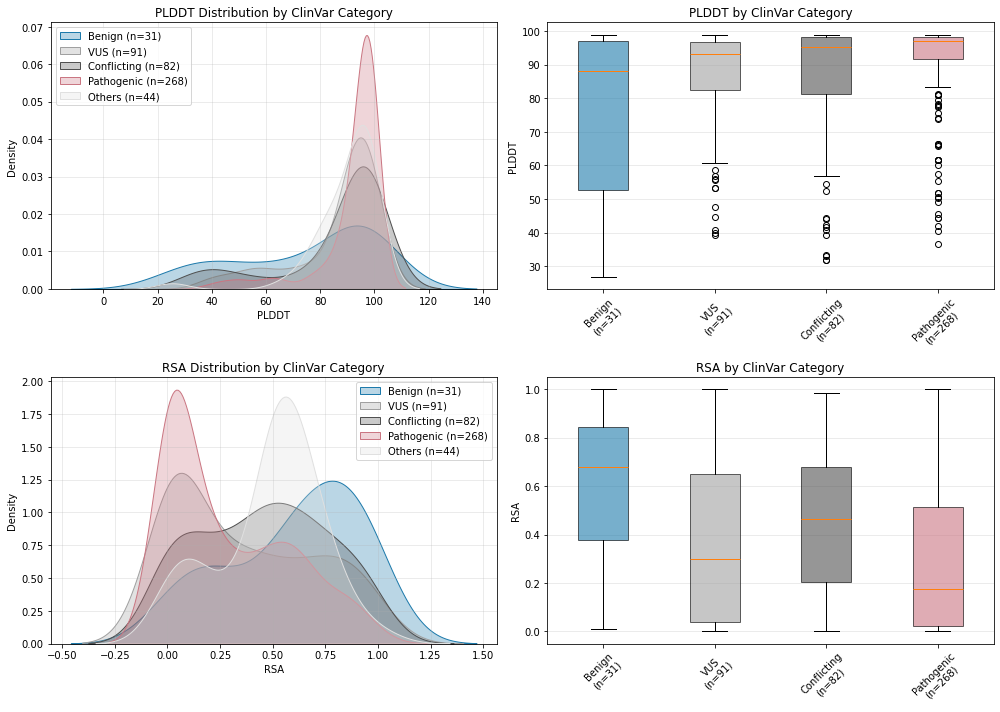

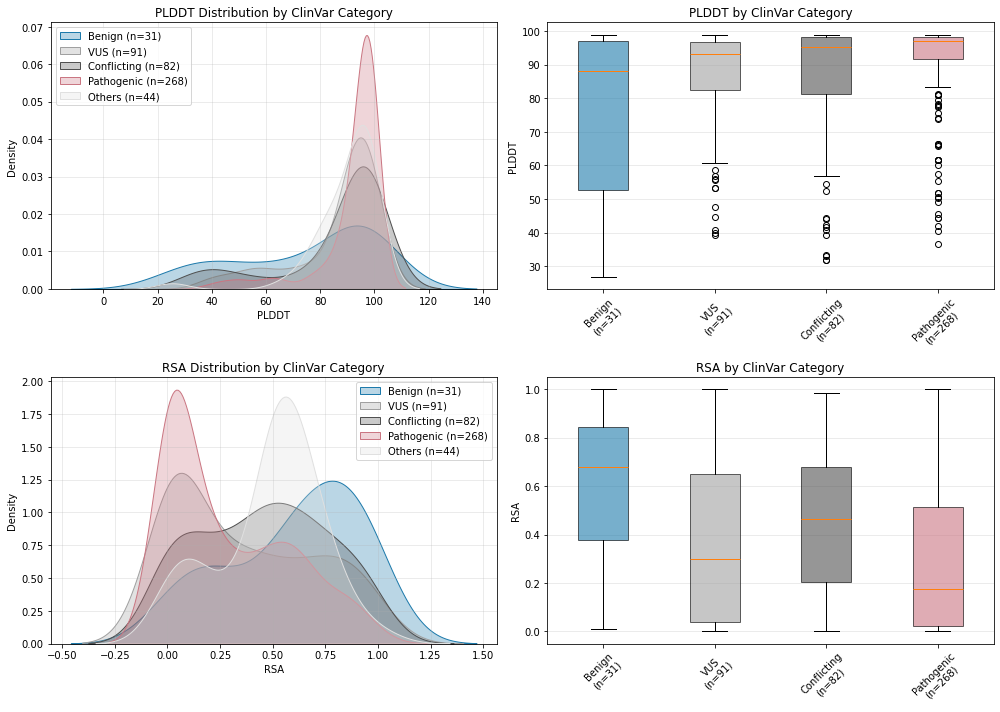

In [ ]:
# Plot pLDDT and RSA for main ClinVar categories
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean'
)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3945754855.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax_box.boxplot(plot_data, labels=plot_labels, patch_artist=True)



PLDDT Statistics by ClinVar Category
Likely benign       : n=  23, mean=76.313, median=88.240, std=23.828
VUS                 : n=  91, mean=86.307, median=93.220, std=16.195
Conflicting         : n=  81, mean=84.824, median=95.040, std=20.516
Pathogenic          : n= 166, mean=90.420, median=96.235, std=13.825
Others              : n=  50, mean=89.847, median=95.795, std=12.893
Likely pathogenic   : n=  97, mean=93.818, median=97.620, std=9.638
Benign              : n=   8, mean=69.611, median=78.930, std=31.767

RSA Statistics by ClinVar Category
Likely benign       : n=  23, mean=0.545, median=0.560, std=0.319
VUS                 : n=  91, mean=0.363, median=0.297, std=0.333
Conflicting         : n=  81, mean=0.459, median=0.466, std=0.302
Pathogenic          : n= 166, mean=0.312, median=0.231, std=0.300
Others              : n=  50, mean=0.459, median=0.533, std=0.255
Likely pathogenic   : n=  97, mean=0.233, median=0.132, std=0.257
Benign              : n=   8, mean=0.748, median

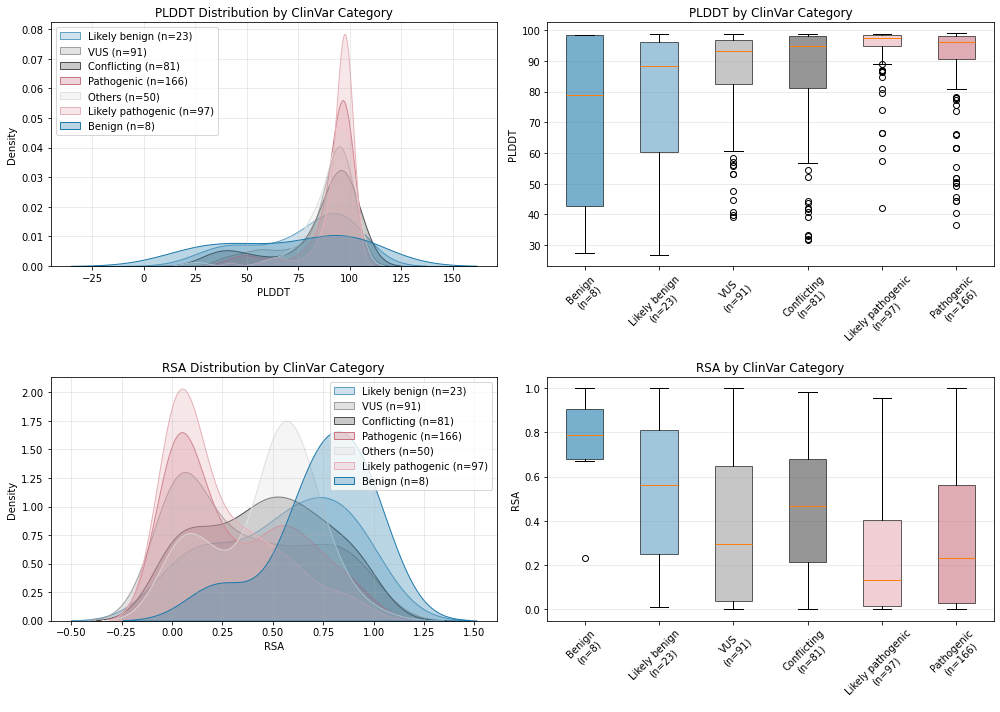

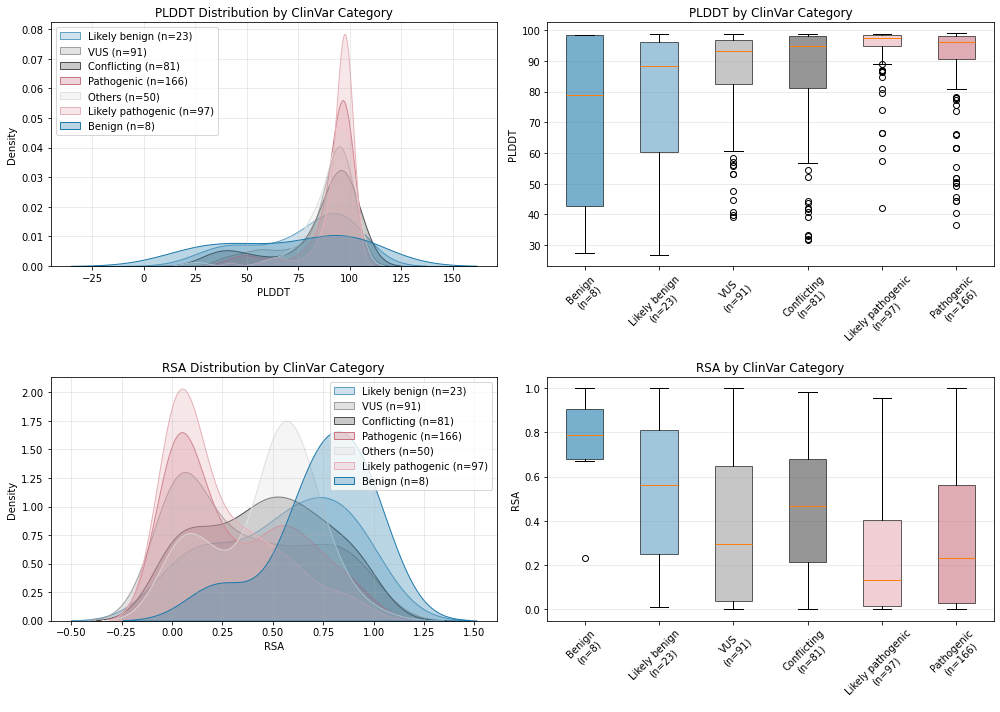

In [ ]:
# Plot using stricter ClinVar classification
plot_structural_features_by_clinvar(
    orf_distances, 
    features=['plddt', 'rsa'],
    clinvar_col='clinvar_clnsig_clean_pp_strict'
)

## scores

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/771649454.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/771649454.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


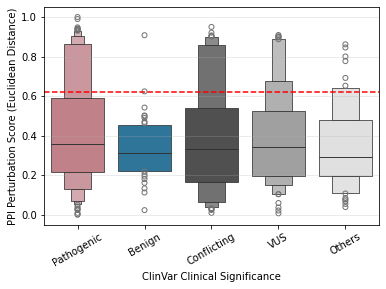

In [243]:

order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.axhline(y=0.620, color='red', linestyle='--', label='LLR Threshold (0.620)')
plt.show()


In [445]:
def add_statistical_annotations(ax, data, x_col, y_col, order=None, test='mannwhitneyu', 
                                comparisons='all_significant', y_offset_factor=0.05, 
                                fontsize=10, alpha=0.05, fdr_correction=True, fdr_method='fdr_bh'):
    """
    Add statistical significance annotations to a plot.
    
    Parameters:
    -----------
    ax : matplotlib.axes.Axes
        The axes object to add annotations to
    data : pl.DataFrame or pd.DataFrame
        DataFrame containing the data
    x_col : str
        Column name for x-axis categories
    y_col : str
        Column name for y-axis values
    order : list, optional
        Order of categories on x-axis
    test : str
        Statistical test to use ('mannwhitneyu', 'ttest', 'kruskal')
    comparisons : str or list of tuples
        'all_significant' to test all pairs and show only significant ones
        'adjacent' for adjacent pairs only
        Or list of specific pairs: [('Pathogenic', 'Benign'), ...]
    y_offset_factor : float
        Vertical offset for annotation bars as fraction of y-range
    fontsize : int
        Font size for significance stars
    alpha : float
        Significance level threshold (default: 0.05)
    fdr_correction : bool
        Whether to apply FDR correction for multiple testing (default: True)
    fdr_method : str
        FDR correction method ('fdr_bh' for Benjamini-Hochberg, 'fdr_by' for Benjamini-Yekutieli)
        
    Returns:
    --------
    dict : Dictionary with test results for each comparison
    """
    from scipy import stats as scipy_stats
    from statsmodels.stats.multitest import multipletests
    import pandas as pd
    import numpy as np
    from itertools import combinations
    
    # Convert to pandas if needed
    if hasattr(data, 'to_pandas'):
        df = data.to_pandas()
    else:
        df = data.copy()
    
    # Get order if not specified
    if order is None:
        order = df[x_col].unique().tolist()
    
    # Filter data for categories in order
    df = df[df[x_col].isin(order)].copy()
    
    # Set up comparisons
    if comparisons == 'all_significant':
        # Test all possible pairs
        all_pairs = list(combinations(order, 2))
    elif comparisons == 'adjacent':
        all_pairs = [(order[i], order[i+1]) for i in range(len(order)-1)]
    else:
        all_pairs = comparisons
    
    # Store all results
    all_results = {}
    
    # Perform tests on all pairs
    for cat1, cat2 in all_pairs:
        # Get data for each category
        data1 = df[df[x_col] == cat1][y_col].dropna()
        data2 = df[df[x_col] == cat2][y_col].dropna()
        
        if len(data1) < 2 or len(data2) < 2:
            continue
        
        # Perform statistical test
        if test == 'mannwhitneyu':
            statistic, p_value = scipy_stats.mannwhitneyu(data1, data2, alternative='two-sided')
            test_name = 'Mann-Whitney U'
        elif test == 'ttest':
            statistic, p_value = scipy_stats.ttest_ind(data1, data2)
            test_name = 't-test'
        elif test == 'kruskal':
            statistic, p_value = scipy_stats.kruskal(data1, data2)
            test_name = 'Kruskal-Wallis'
        
        # Store results
        all_results[f"{cat1}_vs_{cat2}"] = {
            'statistic': statistic,
            'p_value': p_value,
            'test': test_name,
            'n1': len(data1),
            'n2': len(data2),
            'mean1': data1.mean(),
            'mean2': data2.mean(),
            'median1': data1.median(),
            'median2': data2.median(),
            'cat1': cat1,
            'cat2': cat2
        }
    
    # Apply FDR correction if requested
    if fdr_correction and all_results:
        p_values = [v['p_value'] for v in all_results.values()]
        reject, p_adjusted, _, _ = multipletests(p_values, alpha=alpha, method=fdr_method)
        
        # Add adjusted p-values to results
        for (key, result), p_adj, is_reject in zip(all_results.items(), p_adjusted, reject):
            result['p_value_adjusted'] = p_adj
            result['reject_null_fdr'] = is_reject
    
    # Filter for significant results
    if comparisons == 'all_significant':
        if fdr_correction:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v.get('reject_null_fdr', False)}
        else:
            significant_results = {k: v for k, v in all_results.items() 
                                 if v['p_value'] < alpha}
    else:
        significant_results = all_results
    
    if not significant_results:
        correction_text = " (FDR-corrected)" if fdr_correction else ""
        print(f"No significant comparisons found at alpha={alpha}{correction_text}")
        return all_results
    
    # Get y-axis limits for positioning
    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min
    y_offset = y_range * y_offset_factor
    
    # Calculate max y value for starting position
    max_y = df[y_col].max()
    current_y = max_y + y_offset
    
    # Sort comparisons by adjusted p-value if FDR, else by p-value
    sort_key = 'p_value_adjusted' if fdr_correction else 'p_value'
    sorted_comparisons = sorted(significant_results.items(), 
                               key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    # Add annotations for significant results
    for comparison_name, stats in sorted_comparisons:
        cat1 = stats['cat1']
        cat2 = stats['cat2']
        
        # Use adjusted p-value if FDR correction is applied
        p_value = stats.get('p_value_adjusted', stats['p_value']) if fdr_correction else stats['p_value']
        
        # Determine significance stars
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = '**'
        elif p_value < 0.05:
            sig_text = '*'
        else:
            continue  # Skip non-significant
        
        # Get x positions
        x1 = order.index(cat1)
        x2 = order.index(cat2)
        
        # Draw horizontal line
        ax.plot([x1, x2], [current_y, current_y], 'k-', lw=1.5)
        
        # Draw vertical ticks
        tick_height = y_offset * 0.2
        ax.plot([x1, x1], [current_y, current_y - tick_height], 'k-', lw=1.5)
        ax.plot([x2, x2], [current_y, current_y - tick_height], 'k-', lw=1.5)
        
        # Add significance text
        ax.text((x1 + x2) / 2, current_y + y_offset * 0.1, sig_text,
               ha='center', va='bottom', fontsize=fontsize, fontweight='bold')
        
        # Update y position for next comparison
        current_y += y_offset * 1.5
    
    # Adjust y-axis limit to accommodate annotations
    if sorted_comparisons:
        ax.set_ylim(y_min, current_y + y_offset)
    
    return all_results


def print_statistical_summary(results, verbose=True, alpha=0.05, show_all=False, use_fdr=True):
    """
    Print summary of statistical test results.
    
    Parameters:
    -----------
    results : dict
        Dictionary returned by add_statistical_annotations
    verbose : bool
        Whether to print detailed output
    alpha : float
        Significance threshold for highlighting
    show_all : bool
        If True, show all comparisons; if False, show only significant ones
    use_fdr : bool
        Whether to use FDR-adjusted p-values for filtering (if available)
    """
    if not verbose:
        return
    
    # Check if FDR correction was applied
    has_fdr = any('p_value_adjusted' in v for v in results.values())
    
    # Filter results if requested
    if show_all:
        display_results = results
        title = "All Statistical Test Results"
    else:
        if has_fdr and use_fdr:
            display_results = {k: v for k, v in results.items() 
                             if v.get('reject_null_fdr', False)}
            title = f"Significant Statistical Test Results (FDR-corrected, alpha={alpha})"
        else:
            display_results = {k: v for k, v in results.items() 
                             if v['p_value'] < alpha}
            title = f"Significant Statistical Test Results (p < {alpha})"
    
    if not display_results:
        fdr_text = " (FDR-corrected)" if (has_fdr and use_fdr) else ""
        print(f"\nNo {'significant ' if not show_all else ''}results to display{fdr_text}")
        return
    
    print(f"\n{'='*80}")
    print(title)
    print(f"{'='*80}")
    print(f"Total comparisons: {len(results)}")
    
    if has_fdr:
        print(f"Significant comparisons (FDR): {sum(1 for v in results.values() if v.get('reject_null_fdr', False))}")
    print(f"Significant comparisons (unadjusted): {sum(1 for v in results.values() if v['p_value'] < alpha)}")
    print(f"{'='*80}")
    
    # Sort by adjusted p-value if available, else by p-value
    sort_key = 'p_value_adjusted' if (has_fdr and use_fdr) else 'p_value'
    sorted_results = sorted(display_results.items(), 
                           key=lambda x: x[1].get(sort_key, x[1]['p_value']))
    
    for comparison, stats in sorted_results:
        cat1, cat2 = comparison.replace('_vs_', ' vs ').split(' vs ')
        print(f"\n{cat1} vs {cat2}:")
        print(f"  Test: {stats['test']}")
        print(f"  Statistic: {stats['statistic']:.4f}")
        print(f"  P-value: {stats['p_value']:.4e}")
        
        if has_fdr:
            print(f"  P-value (FDR-adjusted): {stats['p_value_adjusted']:.4e}")
            print(f"  Reject null (FDR): {stats['reject_null_fdr']}")
        
        print(f"  N1: {stats['n1']}, N2: {stats['n2']}")
        print(f"  Mean1: {stats['mean1']:.4f}, Mean2: {stats['mean2']:.4f}")
        print(f"  Median1: {stats['median1']:.4f}, Median2: {stats['median2']:.4f}")
        print(f"  Mean difference: {stats['mean1'] - stats['mean2']:.4f}")
        
        # Use adjusted p-value for significance markers if FDR is applied
        p_val = stats.get('p_value_adjusted', stats['p_value']) if (has_fdr and use_fdr) else stats['p_value']
        
        if p_val < 0.001:
            sig = "*** (highly significant)"
        elif p_val < 0.01:
            sig = "** (very significant)"
        elif p_val < 0.05:
            sig = "* (significant)"
        else:
            sig = "ns (not significant)"
        print(f"  Significance: {sig}")
    
    print(f"{'='*80}\n")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2695612756.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2695612756.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


No significant comparisons found at alpha=0.05 (FDR-corrected)


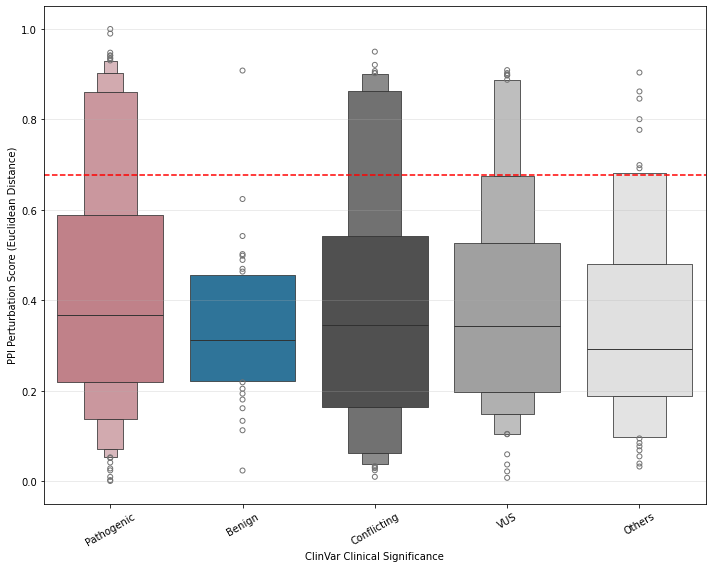


No significant results to display (FDR-corrected)

All Statistical Test Results
Total comparisons: 10
Significant comparisons (FDR): 0
Significant comparisons (unadjusted): 0

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 4368.0000
  P-value: 1.3634e-01
  P-value (FDR-adjusted): 6.8169e-01
  Reject null (FDR): False
  N1: 242, N2: 31
  Mean1: 0.4235, Mean2: 0.3371
  Median1: 0.3675, Median2: 0.3115
  Mean difference: 0.0864
  Significance: ns (not significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 7142.0000
  P-value: 7.7581e-02
  P-value (FDR-adjusted): 6.8169e-01
  Reject null (FDR): False
  N1: 242, N2: 51
  Mean1: 0.4235, Mean2: 0.3539
  Median1: 0.3675, Median2: 0.2922
  Mean difference: 0.0696
  Significance: ns (not significant)

Pathogenic vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 10312.0000
  P-value: 2.1897e-01
  P-value (FDR-adjusted): 6.9490e-01
  Reject null (FDR): False
  N1: 242, N2: 78
  Mean1: 0.4235, Mean2: 0.3874
  Median1:

In [493]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=True,  # Apply FDR correction
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

No significant comparisons found at alpha=0.05


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/463325278.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/463325278.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


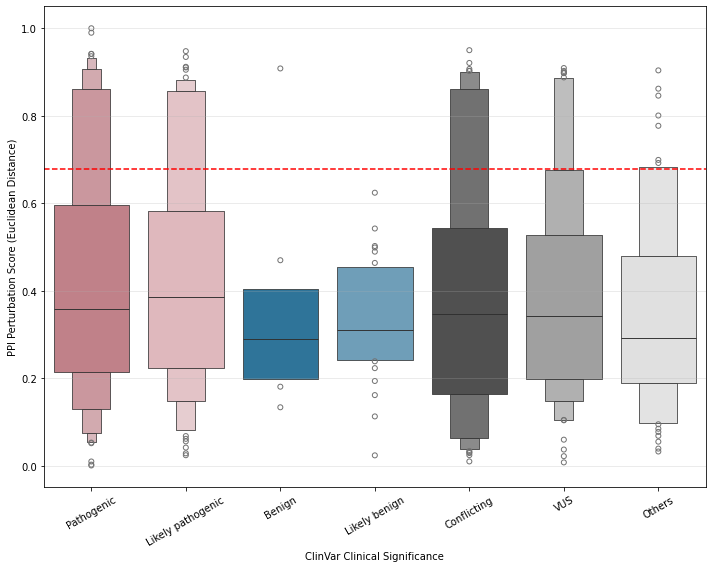


No significant results to display

All Statistical Test Results
Total comparisons: 21
Significant comparisons: 0

Likely pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 2681.0000
  P-value: 7.5128e-02
  N1: 89, N2: 51
  Mean1: 0.4278, Mean2: 0.3539
  Median1: 0.3864, Median2: 0.2922
  Mean difference: 0.0739
  Significance: ns (not significant)

Pathogenic vs Others:
  Test: Mann-Whitney U
  Statistic: 4461.0000
  P-value: 1.2575e-01
  N1: 153, N2: 51
  Mean1: 0.4210, Mean2: 0.3539
  Median1: 0.3583, Median2: 0.2922
  Mean difference: 0.0671
  Significance: ns (not significant)

Likely pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 1229.0000
  P-value: 1.3980e-01
  N1: 89, N2: 23
  Mean1: 0.4278, Mean2: 0.3301
  Median1: 0.3864, Median2: 0.3115
  Mean difference: 0.0977
  Significance: ns (not significant)

Likely pathogenic vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 3849.0000
  P-value: 2.2593e-01
  N1: 89, N2: 78
  Mean1: 0.4278, Mean2: 0.3874
  

In [ ]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances,
    x_col="clinvar_clnsig_clean_pp_strict",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05  # Can adjust significance threshold
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1893048866.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1893048866.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


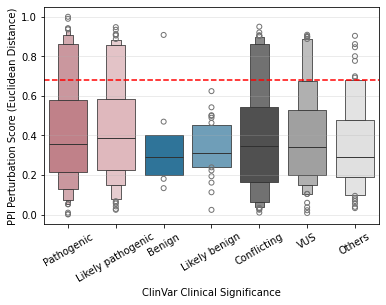

In [307]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2349656510.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2349656510.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


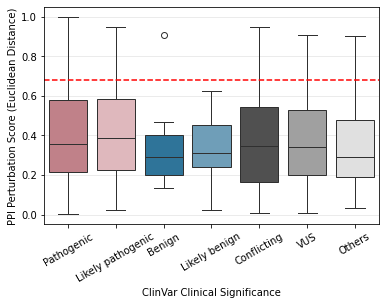

In [246]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3175448014.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3175448014.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


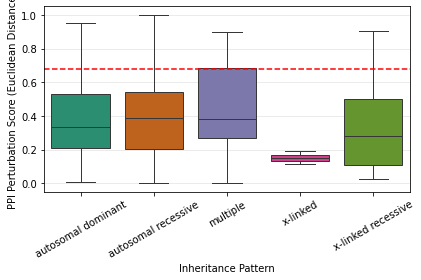

In [278]:

# First check if inheritance_pattern column exists
if "inheritance_pattern" in orf_distances.columns:
    order = ['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
    # Get unique inheritance patterns
    inheritance_order = orf_distances.select("inheritance_pattern").unique().to_series().sort().to_list()
    
    ax = sns.boxplot(
        data=orf_distances,
        x="inheritance_pattern",
        y="normalized_euclid_distance_normalized",
        order=order,
        palette='Dark2',
    )
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
    ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
    plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
    ax.set_xlabel("Inheritance Pattern")
    # plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Column 'inheritance_pattern' not found in orf_distances")
    print("Available columns:", orf_distances.columns)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2915675403.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2915675403.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


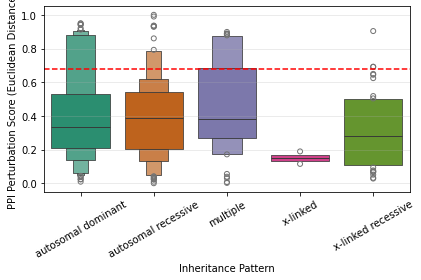

In [288]:

# First check if inheritance_pattern column exists
if "inheritance_pattern" in orf_distances.columns:
    order = ['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
    # Get unique inheritance patterns
    inheritance_order = orf_distances.select("inheritance_pattern").unique().to_series().sort().to_list()
    
    ax = sns.boxenplot(
        data=orf_distances,
        x="inheritance_pattern",
        y="normalized_euclid_distance_normalized",
        order=order,
        palette='Dark2',
    )
    ax.grid(alpha=0.3, axis='y')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
    ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
    plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
    ax.set_xlabel("Inheritance Pattern")
    # plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Column 'inheritance_pattern' not found in orf_distances")
    print("Available columns:", orf_distances.columns)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3966634490.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/3966634490.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


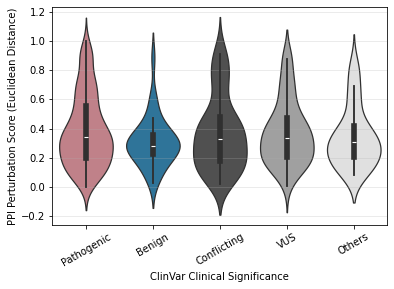

In [ ]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/814735304.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/814735304.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


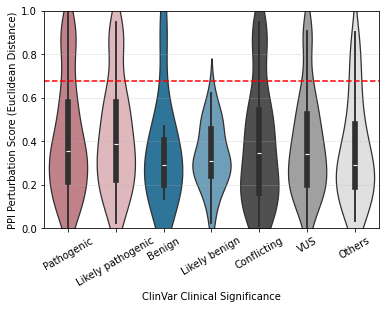

In [306]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.violinplot(
    data=orf_distances,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.ylim(0, 1)
plt.show()


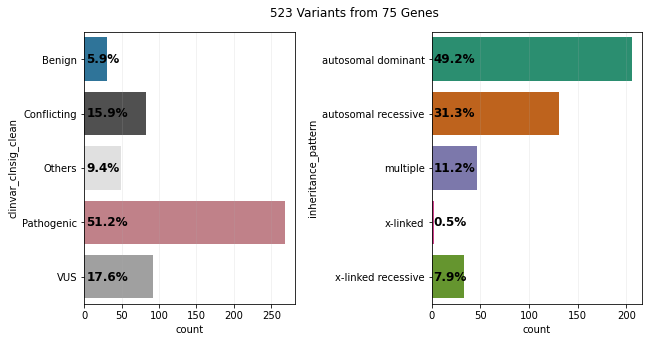

In [ ]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean.isin(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

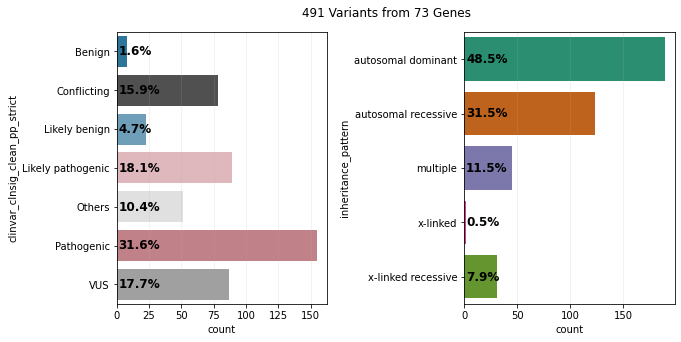

In [247]:
orf_pd = orf_distances.to_pandas()

original_df = pl.DataFrame(orf_pd)

plot_df = orf_pd[orf_pd.clinvar_clnsig_clean_pp_strict.isin(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean_pp_strict",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('gene_variant').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

## hit rates

In [295]:
def plot_assay_hit_by_category(df, hit_col, cat_cols, title="", ax=None, palette_dict=None, xlim=None, order=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a horizontal bar chart showing the hit rate percentage for each
    category in `cat_cols`, colored according to a palette.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"ppi_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    palette_dict : dict, optional
        Dictionary mapping category values to colors. If None, uses default colors.
        For inheritance_pattern, uses seaborn 'Dark2' palette automatically.
    xlim : tuple, optional
        X-axis limits. If None, uses (0, 100) by default.
    order : list, optional
        Order of categories for plotting. If None, uses default sorting.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    
    Example
    -------
    >>> plot_assay_hit_by_category(
    ...     df=my_data,
    ...     hit_col="ppi_hit",
    ...     cat_cols="clinvar_clnsig_clean_pp_strict",
    ...     title="Hit rate by ClinVar significance",
    ...     palette_dict=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ...     order=["Benign", "Likely benign", "VUS", "Conflicting", "Likely pathogenic", "Pathogenic"]
    ... )
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_cols)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(8, max(4, img_hits_perc_df.shape[0] * 0.5)))

    plot_df = img_hits_perc_df.to_pandas()
    
    # Get category column name
    cat_col_name = cat_cols if isinstance(cat_cols, str) else cat_cols[-1]
    
    # Apply custom order if provided
    if order is not None:
        # Filter to only include categories that are in the order list
        plot_df = plot_df[plot_df[cat_col_name].isin(order)]
        # Convert to categorical with specified order
        plot_df[cat_col_name] = pd.Categorical(plot_df[cat_col_name], categories=order, ordered=True)
        plot_df = plot_df.sort_values(cat_col_name, ascending=False).reset_index(drop=True)
    
    # Create color list based on category type
    if cat_cols == 'inheritance_pattern':
        # Use seaborn Dark2 palette for inheritance patterns
        n_categories = len(plot_df[cat_col_name].unique())
        colors = sns.color_palette('Dark2', n_categories)[::-1]
    elif palette_dict is not None:
        # Use provided palette dictionary
        colors = [palette_dict.get(cat, '#808080') for cat in plot_df[cat_col_name]]
    else:
        # Default colors
        colors = None

    # Hit rate bars (colored by category)
    ax.barh(
        y=plot_df[cat_col_name].astype(str),  # Convert to string to avoid categorical issues
        width=plot_df["hit_perc"],
        color=colors
    )

    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel("Hit Rate (%)", fontsize=12)
    ax.set_ylabel("")
    ax.grid(alpha=.2, axis='x')
    
    # Set x-axis limits
    if xlim is not None:
        ax.set_xlim(xlim)
    else:
        ax.set_xlim(0, 100)

    # Percentage annotations
    for idx, row in plot_df.iterrows():
        ax.text(
            row['hit_perc'] + 1,
            idx,
            f"{row['hit_perc']:.1f}% ({int(row['hit_counts'])}/{int(row['total_counts'])})",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=10,
            color="black"
        )

    plt.tight_layout()
    return img_hits_perc_df

In [466]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean").is_in(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others']) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

ColumnNotFoundError: unable to find column "ppi_hit"; valid columns: ["db_orf_id", "db_mut_id", "euclid_distance", "num_edges", "normalized_euclid_distance", "normalized_euclid_distance_normalized", "symbol", "ensembl_gene_id", "ccsb_mutation_id", "ccsb_allele_id", "spdi", "nt_change", "aa_change", "seq", "seq_aa", "collection", "entry_plate_orig", "entry_well_orig", "entry_plate_conso", "entry_well_conso", "entry_seq_pool", "db_plate", "db_well", "n2h_plate", "n2h_well", "dualip_plate", "dualip_well", "mislocalization_plate", "mislocalization_well", "entry_sequenced", "entry_sequence_confirmation_class", "db_sequenced", "db_sequence_confirmation_class", "n2h_sequenced", "n2h_sequence_confirmation_class", "n2h_ref_sequence_confirmation_class", "dualip_sequenced", "dualip_sequence_confirmation_class", "dualip_ref_sequence_confirmation_class", "mislocalization_sequenced", "mislocalization_sequence_confirmation_class", "mislocalization_ref_sequence_confirmation_class", "chr_num", "nuc_loc

clinvar_clnsig_clean_pp_strict,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""Benign""",8,1,12.5
"""Conflicting""",78,13,16.666667
"""Likely benign""",23,0,0.0
"""Likely pathogenic""",89,16,17.977528
"""Others""",51,7,13.72549
"""Pathogenic""",155,32,20.645161
"""VUS""",87,11,12.643678


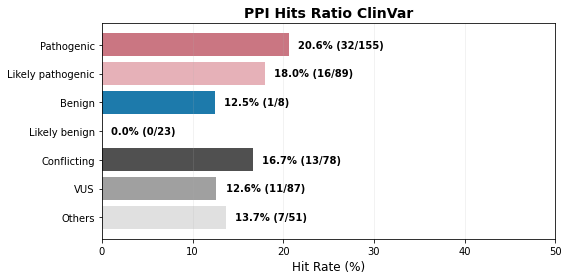

In [297]:
scores_dedup_with_gene_variant = orf_distances.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant,
                           "ppi_hit", 
                           "clinvar_clnsig_clean_pp_strict", 
                           f"PPI Hits Ratio ClinVar", 
                           xlim=(0,50),
                           order=["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"],
                           palette_dict=palette_dict["clinvar_clnsig_clean_pp_strict"])

inheritance_pattern,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""autosomal dominant""",189,36,19.047619
"""autosomal recessive""",123,12,9.756098
"""multiple""",45,12,26.666667
"""x-linked""",2,0,0.0
"""x-linked dominant""",5,0,0.0
"""x-linked recessive""",31,3,9.677419


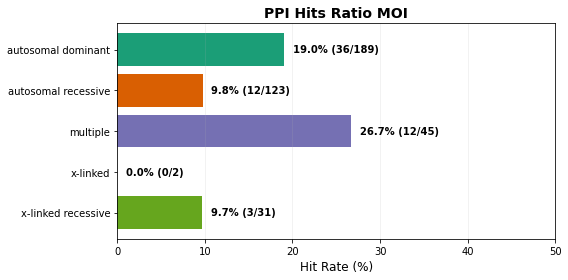

In [298]:
plot_df = orf_distances.filter(
    (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"])) &
    (pl.col('inheritance_pattern').is_not_null())
)

plot_assay_hit_by_category(plot_df, 
                           "ppi_hit", 
                           "inheritance_pattern", 
                           f"PPI Hits Ratio MOI", 
                           xlim=(0,50),
                           order=['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive']
                           )

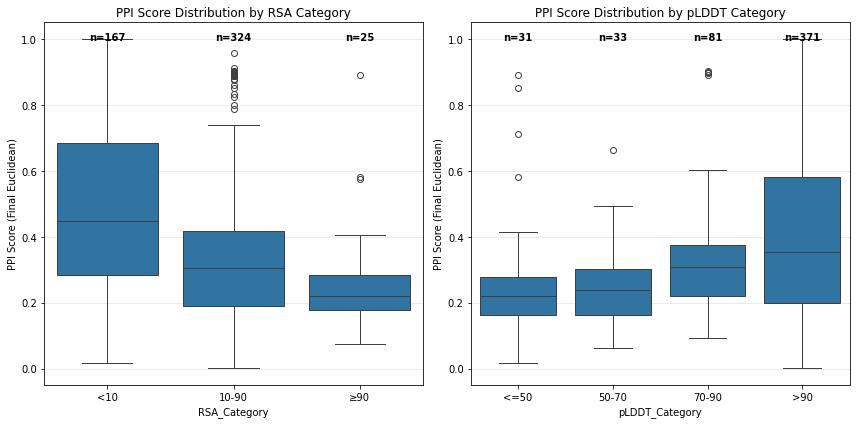

RSA Category Summary:
              count   mean  median    std
RSA_Category                             
<10             167  0.464   0.448  0.251
10-90           324  0.335   0.304  0.217
≥90              25  0.272   0.220  0.183

pLDDT Category Summary:
                count   mean  median    std
pLDDT_Category                             
<=50               31  0.278   0.220  0.214
50-70              33  0.253   0.239  0.132
70-90              81  0.329   0.307  0.175
>90               371  0.402   0.354  0.249


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/1429374680.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_76677/1429374680.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)


In [ ]:
# Set the proper order for both RSA and pLDDT categories
rsa_order = ['<10', '10-90', '≥90']
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()

# Set categorical order for both RSA and pLDDT
all_variants_df_ppi_pd['RSA_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['RSA_Category'], 
    categories=rsa_order, 
    ordered=True
)
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# RSA Category boxplot
rsa_data = all_variants_df_ppi_pd.dropna(subset=['RSA_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=rsa_data, x='RSA_Category', y='normalized_euclid_distance_normalized', ax=axes[0])
axes[0].set_title('PPI Score Distribution by RSA Category')
axes[0].set_ylabel('PPI Score (Final Euclidean)')
axes[0].grid(alpha=0.3, axis='y')

# Add sample sizes for RSA categories (using ordered categories)
for i, category in enumerate(rsa_order):
    n = len(rsa_data[rsa_data['RSA_Category'] == category])
    axes[0].text(i, axes[0].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

# pLDDT Category boxplot  
plddt_data = all_variants_df_ppi_pd.dropna(subset=['pLDDT_Category', 'normalized_euclid_distance_normalized'])
sns.boxplot(data=plddt_data, x='pLDDT_Category', y='normalized_euclid_distance_normalized', ax=axes[1])
axes[1].set_title('PPI Score Distribution by pLDDT Category')
axes[1].set_ylabel('PPI Score (Final Euclidean)')
axes[1].grid(alpha=0.3, axis='y')

# Add sample sizes for pLDDT categories
for i, category in enumerate(plddt_order):
    n = len(plddt_data[plddt_data['pLDDT_Category'] == category])
    axes[1].text(i, axes[1].get_ylim()[1] * 0.95, f'n={n}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("RSA Category Summary:")
rsa_summary = rsa_data.groupby('RSA_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(rsa_summary)

print("\npLDDT Category Summary:")
plddt_summary = plddt_data.groupby('pLDDT_Category')['normalized_euclid_distance_normalized'].agg(['count', 'mean', 'median', 'std']).round(3)
print(plddt_summary)

pLDDT_Category,total_counts,hit_counts,hit_perc
cat,u32,u32,f64
"""50-70""",33,1,3.030303
"""70-90""",81,4,4.938272
"""<=50""",31,3,9.677419
""">90""",371,78,21.024259


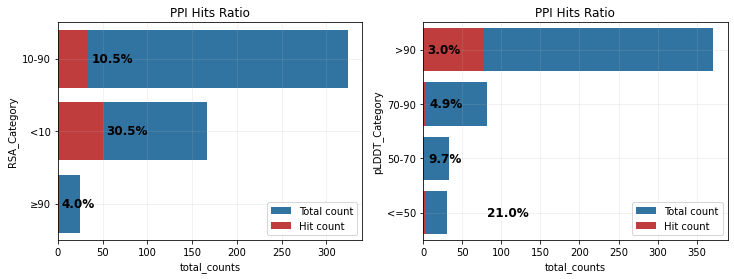

In [ ]:
# Set the proper order for pLDDT categories
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = orf_distances.to_pandas()
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

fig, axes = plt.subplots(1,2,figsize=(12,4))
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='RSA_Category'), "ppi_hit", "RSA_Category", f"PPI Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(all_variants_df_ppi_pl.drop_nulls(subset='pLDDT_Category'), "ppi_hit", "pLDDT_Category", f"PPI Hits Ratio", ax=axes[1])

## Balanced AUPRC

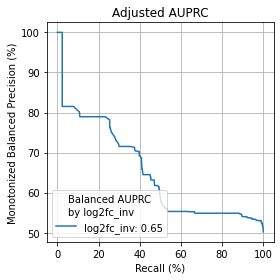

In [162]:
sys.path.insert(1, "../../../4_compare_ai_scores/2_analysis/scripts")
from yogiroc import *

def plot_adjusted_pr_curves(df_clinvar_w_scores, label, pos_labels, methods, monotonized_flag=True, balanced_flag=True, subsample=False, n_bootstrap=1000, random_state=None):
    """
    For each method, plot the adjusted PR curve (with both balanced and monotonized adjustments)
    and compute the adjusted AUPRC via bootstrapping. Also perform pairwise significance testing 
    of the AUPRC across different RSA categories.
    
    Parameters
    ----------
    df_clinvar_w_scores : Polars DataFrame
        Input data including columns "clinvar_clnsig_clean", category and predictor scores.
    methods : list of str
        List of method names corresponding to score columns in the data.
    set2_palette : list of str
        List of colors (e.g., from a color palette) to use for different RSA categories.
    n_bootstrap : int, optional
        Number of bootstrap iterations for significance testing (default is 1000).
    random_state : int or None, optional
        Seed for reproducibility.
    
    Returns
    -------
    ap_results : dict
        Dictionary of adjusted AUPRC values and bootstrap distributions, structured as:
          { method: { category: {"AP": <adjusted AUPRC>, "boot_ap": <bootstrap array> } } }
    significance : dict
        Dictionary mapping each method to a DataFrame of pairwise p-values comparing AUPRC between categories.
    """
    assert (balanced_flag and not subsample) or (subsample and not balanced_flag) or (not subsample and not balanced_flag)
    
    ap_results_dict = {}
    # sig_results_dict = {}
    fig, axes = plt.subplots(1, len(methods), figsize=(4 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
        
    ap_results = {}  # to store adjusted AUPRC and bootstrap distributions
    for m_idx, met in enumerate(methods):
        ap_results[met] = {}
        # Filter data for current category and valid clinical labels.
        df_clin_per_method = df_clinvar_w_scores.with_columns(
            (
                pl.when(pl.col(label).is_in(pos_labels))
                .then(1)
                .otherwise(0)
            ).alias("clinvar_label")
        ).drop_nulls(subset=[label, met])
        
        # Convert to pandas DataFrame.
        df_pd = df_clin_per_method.to_pandas()
        if subsample:
            # Assume df is your existing DataFrame with a column named "label"
            # Find the minimum count among the two classes (0 and 1)
            min_count = df_pd['clinvar_label'].value_counts().min()
            # Group by the 'label' column and sample min_count rows from each group (without replacement)
            df_pd = df_pd.groupby('clinvar_label').apply(lambda x: x.sample(n=min_count, random_state=42)).reset_index(drop=True)

        # Convert clinvar_label to boolean.
        truth = df_pd["clinvar_label"].astype(bool)
        # Create a scores DataFrame (with one column).
        scores = df_pd[[met]]

        # Create the YogiROC2 object using the new YogiROC2() constructor.
        yrobj = YogiROC2(truth, scores, names=[met], high=True)
        # Get the performance table from the YogiROC2 object.
        table = yrobj.tables[met]

        if (monotonized_flag and balanced_flag):
            table = table.dropna()
        precision = configure_prec(table, monotonized_flag=monotonized_flag, balanced_flag=balanced_flag)
        recall = table["tpr_sens"].values
        # print(precision)
        # print(recall)
        ap = calc_auc(recall[~np.isnan(recall)], precision[~np.isnan(precision)])
        ap_results[met] = {"AUPRC": ap}

        # Plot the adjusted PR curve.
        axes[m_idx].plot(100 * recall, 100 * precision,
                        label=f"{met}: {ap:.2f}")
        # Plot chance level as a horizontal dashed line.
        prior = np.sum(truth) / df_pd.shape[0]
        if (not balanced_flag):
            axes[m_idx].axhline(y=100 * prior, color=set2_palette[plddt_cats.index(cat)], ls="--")
    
        # Customize the subplot.
        handles, labels = axes[methods.index(met)].get_legend_handles_labels()
        precision_label = "Precision (%)"
        title = f"AUPRC\nby {met}"
        
        if balanced_flag:
            precision_label = "Balanced " + precision_label
            title = "Balanced " + title
        if monotonized_flag:
            precision_label = "Monotonized " + precision_label
    
        axes[m_idx].legend(
                        loc="lower left",
                        title=title)
        axes[m_idx].set_xlabel("Recall (%)")
        axes[m_idx].set_ylabel(precision_label)
        axes[m_idx].set_title("Adjusted AUPRC")
        axes[m_idx].grid()

    # sig_results_dict[category] = significance

    plt.tight_layout()
    plt.show()
    # plt.subplots_adjust(wspace=0.04)
    
    return None ## , sig_results_dict

plot_adjusted_pr_curves(df_clinvar_w_scores=df.with_columns(
        (-pl.col("log2fc")).alias("log2fc_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["log2fc_inv"]
)

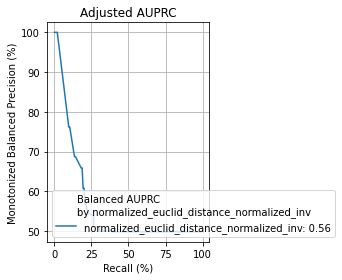

In [164]:
plot_adjusted_pr_curves(df_clinvar_w_scores=orf_distances.with_columns(
        (-pl.col("normalized_euclid_distance_normalized")).alias("normalized_euclid_distance_normalized_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign", "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["normalized_euclid_distance_normalized_inv"]
)

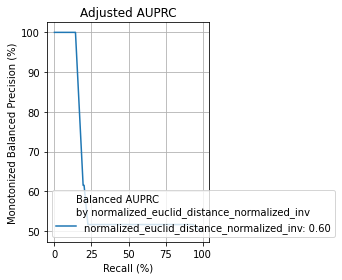

In [165]:
plot_adjusted_pr_curves(df_clinvar_w_scores=orf_distances.with_columns(
        (-pl.col("normalized_euclid_distance_normalized")).alias("normalized_euclid_distance_normalized_inv")
    ).filter(
        (pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely_pathogenic", "Benign"]))#, "Likely benign"]))
    ), 
    label="clinvar_clnsig_clean_pp_strict",
    pos_labels=["Pathogenic", "Likely_pathogenic"], 
    methods=["normalized_euclid_distance_normalized_inv"]
)

In [201]:
orf_distances.to_pandas()

,db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,...,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
0,3689,214816,0.431666,2,0.305234,0.330047,GCK,ENSG00000106633,CCSBVarC006686,ALE00006684,...,0.000000,>90,<10,125851,autosomal dominant,OMIM,Rare genetic developmental defect during embry...,3,"MATURITY-ONSET DIABETES OF THE YOUNG, TYPE 2",False
1,8999,202976,0.201004,1,0.201004,0.217344,TTR,ENSG00000118271,CCSBVarC006246,ALE00006246,...,0.000000,>90,<10,105210,autosomal dominant,OMIM,Rare genetic systemic or rheumatologic disease...,3,"AMYLOIDOSIS, HEREDITARY SYSTEMIC 1",False
2,100016069,2606,1.189002,2,0.840751,0.909098,KCNJ2,ENSG00000123700,CCSBVarC008313,ALE00008299,...,88.679245,70-90,10-90,170390;609622,autosomal dominant,OMIM,Rare genetic cardiac disease; Rare genetic neu...,2,ANDERSEN CARDIODYSRHYTHMIC PERIODIC PARALYSIS;...,False
3,71001,205675,1.155844,18,0.272435,0.294582,UBQLN2,ENSG00000188021,CCSBVarC003504,ALE00003504,...,81.617645,50-70,10-90,300857,x-linked dominant,OMIM,None,0,AMYOTROPHIC LATERAL SCLEROSIS 15 WITH OR WITHO...,False
4,3180,214556,0.525696,9,0.175232,0.189477,NAA10,ENSG00000102030,CCSBVarC005876,ALE00005876,...,85.887100,>90,10-90,300855,x-linked,OMIM,Rare genetic eye disease; Rare genetic develop...,3,OGDEN SYNDROME,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
486,52920,2681,1.227508,15,0.316941,0.342706,LITAF,ENSG00000189067,CCSBVarC007939,ALE00007925,...,88.235300,70-90,10-90,601098,autosomal dominant,OMIM,Rare genetic neurological disorder,1,"CHARCOT-MARIE-TOOTH DISEASE, DEMYELINATING, TY...",False
487,2920,214422,0.388436,5,0.173714,0.187835,GFAP,ENSG00000131095,CCSBVarC004669,ALE00004669,...,68.548386,>90,10-90,203450,autosomal dominant,OMIM,Rare genetic eye disease; Rare genetic neurolo...,2,ALEXANDER DISEASE,False
488,8999,203003,0.198239,1,0.198239,0.214354,TTR,ENSG00000118271,CCSBVarC006261,ALE00006261,...,56.185566,>90,10-90,105210,autosomal dominant,OMIM,Rare genetic systemic or rheumatologic disease...,3,"AMYLOIDOSIS, HEREDITARY SYSTEMIC 1",False
489,11805,2150,0.256696,2,0.181512,0.196267,SMAD3,ENSG00000166949,CCSBVarC004695,ALE00004695,...,80.147060,>90,10-90,613795,autosomal dominant,OMIM,Rare genetic vascular disease; Rare genetic sy...,2,LOEYS-DIETZ SYNDROME 3,False


In [200]:
orf_distances.to_pandas()[orf_distances.to_pandas().clinvar_clnsig_clean_pp_strict.isin(["Benign"])][['gene_variant','symbol','aa_change','clinvar_clnsig_clean_pp_strict','normalized_euclid_distance_normalized']]

,gene_variant,symbol,aa_change,clinvar_clnsig_clean_pp_strict,normalized_euclid_distance_normalized
109,VHL_Pro81Ser,VHL,Pro81Ser,Benign,0.360236
279,VHL_Pro25Leu,VHL,Pro25Leu,Benign,0.382717
366,AGXT_Val326Ile,AGXT,Val326Ile,Benign,0.180828
420,KCNJ2_Ile258Thr,KCNJ2,Ile258Thr,Benign,0.908160
438,KRT8_Tyr54His,KRT8,Tyr54His,Benign,0.133771
463,AGXT_Asn22Ser,AGXT,Asn22Ser,Benign,0.469845
471,KRT8_Gly434Ser,KRT8,Gly434Ser,Benign,0.204817
490,VHL_Glu52Lys,VHL,Glu52Lys,Benign,0.218914


# Genes with signal?

In [173]:
# def select_discriminating_genes(orf_distances, clinvar_col="clinvar_clnsig_clean_pp_strict", 
#                                 metric="normalized_euclid_distance_normalized",
#                                 min_pathogenic=2, min_benign=2, 
#                                 effect_size_threshold=0.3, p_value_threshold=0.05,
#                                 verbose=True):
#     """
#     Select genes that show significant discrimination between benign and pathogenic variants.
    
#     Parameters:
#     -----------
#     orf_distances : pl.DataFrame
#         DataFrame with variant-level scores and ClinVar annotations
#     clinvar_col : str
#         Column to use for ClinVar classification
#     metric : str
#         Column containing the score metric
#     min_pathogenic : int
#         Minimum number of pathogenic variants required per gene
#     min_benign : int
#         Minimum number of benign variants required per gene
#     effect_size_threshold : float
#         Minimum Cohen's d effect size (0.2=small, 0.5=medium, 0.8=large)
#     p_value_threshold : float
#         Maximum p-value for statistical significance
#     verbose : bool
#         Whether to print detailed statistics
        
#     Returns:
#     --------
#     tuple : (discriminating_genes, gene_stats_df)
#         - discriminating_genes: list of gene symbols that meet criteria
#         - gene_stats_df: pl.DataFrame with statistics for each gene
#     """
#     from scipy import stats
    
#     # Define pathogenic and benign categories
#     if clinvar_col == "clinvar_clnsig_clean_pp_strict":
#         pathogenic_categories = ['Pathogenic', 'Likely pathogenic']
#         benign_categories = ['Benign', 'Likely benign']
#     else:
#         pathogenic_categories = ['Pathogenic']
#         benign_categories = ['Benign']
    
#     # Convert to pandas for easier groupby operations
#     df_pd = orf_distances.to_pandas()
    
#     # Filter for genes with sufficient benign and pathogenic variants
#     gene_stats = []
    
#     for gene in df_pd['symbol'].unique():
#         if pd.isna(gene):
#             continue
            
#         gene_data = df_pd[df_pd['symbol'] == gene].copy()
        
#         # Get pathogenic and benign scores
#         path_scores = gene_data[
#             gene_data[clinvar_col].isin(pathogenic_categories)
#         ][metric].dropna()
        
#         benign_scores = gene_data[
#             gene_data[clinvar_col].isin(benign_categories)
#         ][metric].dropna()
        
#         # Skip if insufficient data
#         if len(path_scores) < min_pathogenic or len(benign_scores) < min_benign:
#             continue
        
#         # Calculate statistics
#         # Mann-Whitney U test (non-parametric)
#         statistic, p_value = stats.mannwhitneyu(path_scores, benign_scores, 
#                                                  alternative='two-sided')
        
#         # Cohen's d effect size
#         pooled_std = np.sqrt(
#             ((len(path_scores) - 1) * path_scores.std()**2 + 
#              (len(benign_scores) - 1) * benign_scores.std()**2) / 
#             (len(path_scores) + len(benign_scores) - 2)
#         )
#         cohens_d = abs(path_scores.mean() - benign_scores.mean()) / pooled_std if pooled_std > 0 else 0
        
#         # Area under ROC curve (simple version)
#         from sklearn.metrics import roc_auc_score
#         y_true = [1] * len(path_scores) + [0] * len(benign_scores)
#         y_scores = list(path_scores) + list(benign_scores)
#         try:
#             auroc = roc_auc_score(y_true, y_scores)
#         except:
#             auroc = 0.5
        
#         gene_stats.append({
#             'symbol': gene,
#             'db_orf_id': gene_data['db_orf_id'].iloc[0],
#             'n_pathogenic': len(path_scores),
#             'n_benign': len(benign_scores),
#             'pathogenic_mean': path_scores.mean(),
#             'pathogenic_median': path_scores.median(),
#             'benign_mean': benign_scores.mean(),
#             'benign_median': benign_scores.median(),
#             'mean_difference': path_scores.mean() - benign_scores.mean(),
#             'cohens_d': cohens_d,
#             'mannwhitney_p': p_value,
#             'auroc': auroc
#         })
    
#     # Convert to DataFrame
#     gene_stats_df = pl.DataFrame(gene_stats)
    
#     # Filter for discriminating genes
#     discriminating_genes_df = gene_stats_df.filter(
#         (pl.col('cohens_d') >= effect_size_threshold) &
#         (pl.col('mannwhitney_p') <= p_value_threshold)
#     ).sort('cohens_d', descending=True)
    
#     discriminating_genes = discriminating_genes_df['symbol'].to_list()
    
#     if verbose:
#         print(f"\n{'='*80}")
#         print(f"Gene Discrimination Analysis")
#         print(f"{'='*80}")
#         print(f"Total genes analyzed: {len(gene_stats)}")
#         print(f"Genes meeting criteria: {len(discriminating_genes)}")
#         print(f"\nCriteria:")
#         print(f"  - Min pathogenic variants: {min_pathogenic}")
#         print(f"  - Min benign variants: {min_benign}")
#         print(f"  - Min Cohen's d: {effect_size_threshold}")
#         print(f"  - Max p-value: {p_value_threshold}")
#         print(f"\nTop 10 discriminating genes:")
#         print(discriminating_genes_df.head(10).to_pandas().to_string(index=False))
#         print(f"{'='*80}\n")
    
#     return discriminating_genes, gene_stats_df

# # Use the function
# discriminating_genes, gene_stats = select_discriminating_genes(
#     orf_distances,
#     clinvar_col="clinvar_clnsig_clean_pp_strict",
#     metric="normalized_euclid_distance_normalized",
#     min_pathogenic=1,
#     min_benign=1,
#     effect_size_threshold=0.2,  # Medium effect size
#     p_value_threshold=0.7,
#     verbose=True
# )

# # Filter your data to only these genes
# orf_distances_filtered = orf_distances.filter(
#     pl.col("symbol").is_in(discriminating_genes)
# )

# print(f"\nFiltered to {len(discriminating_genes)} genes with "
#       f"{orf_distances_filtered.height} variants")


Gene Discrimination Analysis
Total genes analyzed: 13
Genes meeting criteria: 3

Criteria:
  - Min pathogenic variants: 1
  - Min benign variants: 1
  - Min Cohen's d: 0.2
  - Max p-value: 0.7

Top 10 discriminating genes:
symbol  db_orf_id  n_pathogenic  n_benign  pathogenic_mean  pathogenic_median  benign_mean  benign_median  mean_difference  cohens_d  mannwhitney_p    auroc
STXBP1       7652            15         2         0.850723           0.867963     0.238192       0.238192         0.612532 13.533932       0.014706 1.000000
 AIPL1       7167             2         2         0.162378           0.162378     0.309608       0.309608        -0.147230  0.918311       0.666667 0.250000
  AGXT      70497            12         6         0.404245           0.525710     0.327750       0.325336         0.076495  0.397801       0.290778 0.666667


Filtered to 3 genes with 74 variants


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3132905981.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3132905981.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(category_labels, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3132905981.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3132905981.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set

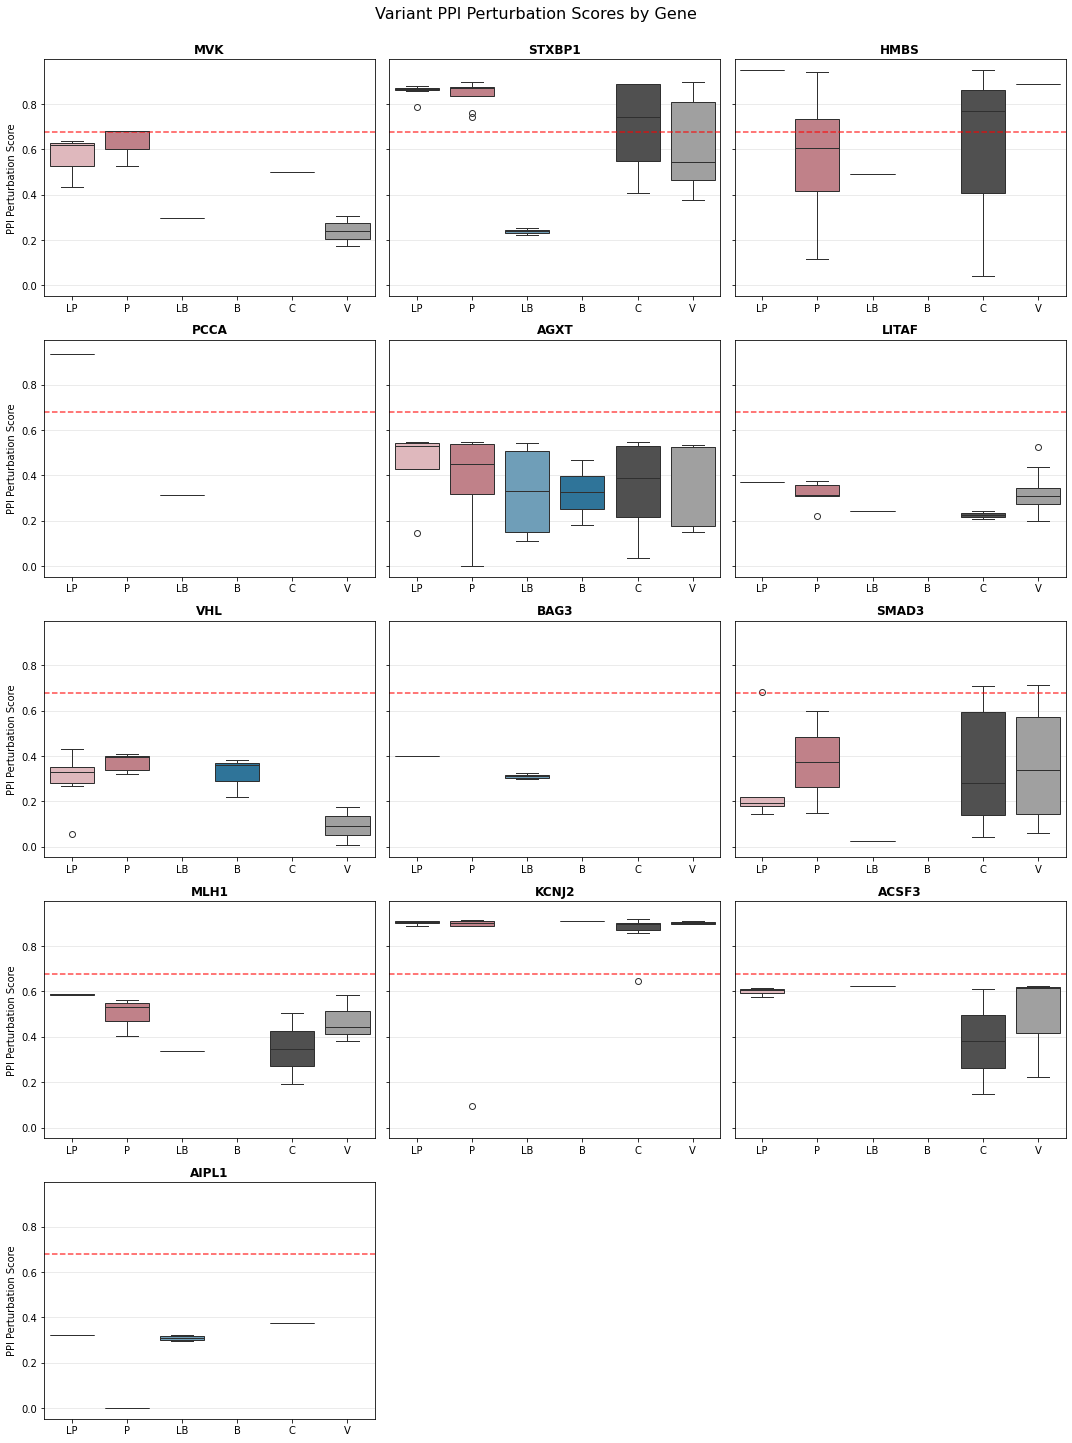

In [384]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Likely pathogenic", "Pathogenic", "Likely benign", "Benign", "Conflicting", "VUS"]
category_labels = ["LP", "P", "LB", "B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxplot(
            data=gene_df,
            x="clinvar_clnsig_clean_pp_strict",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Set custom x-tick labels
        ax.set_xticklabels(category_labels, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2233362604.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2233362604.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(category_labels, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2233362604.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2233362604.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set

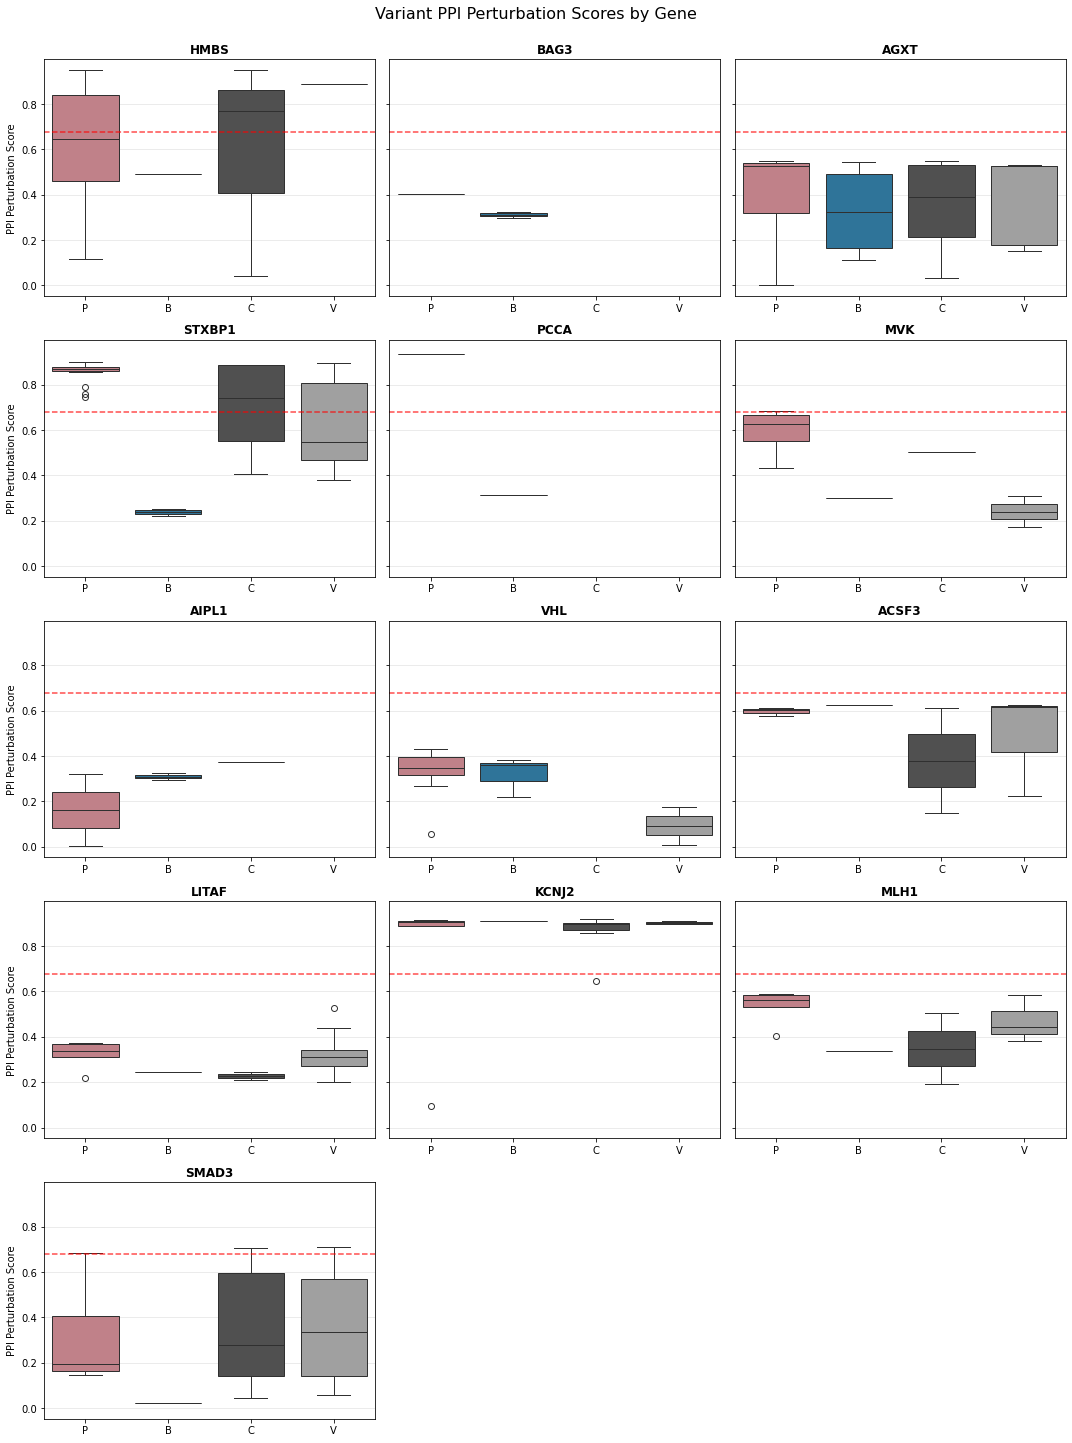

In [441]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Set custom x-tick labels
        ax.set_xticklabels(category_labels, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3445851691.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3445851691.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3445851691.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/3445851691.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. af

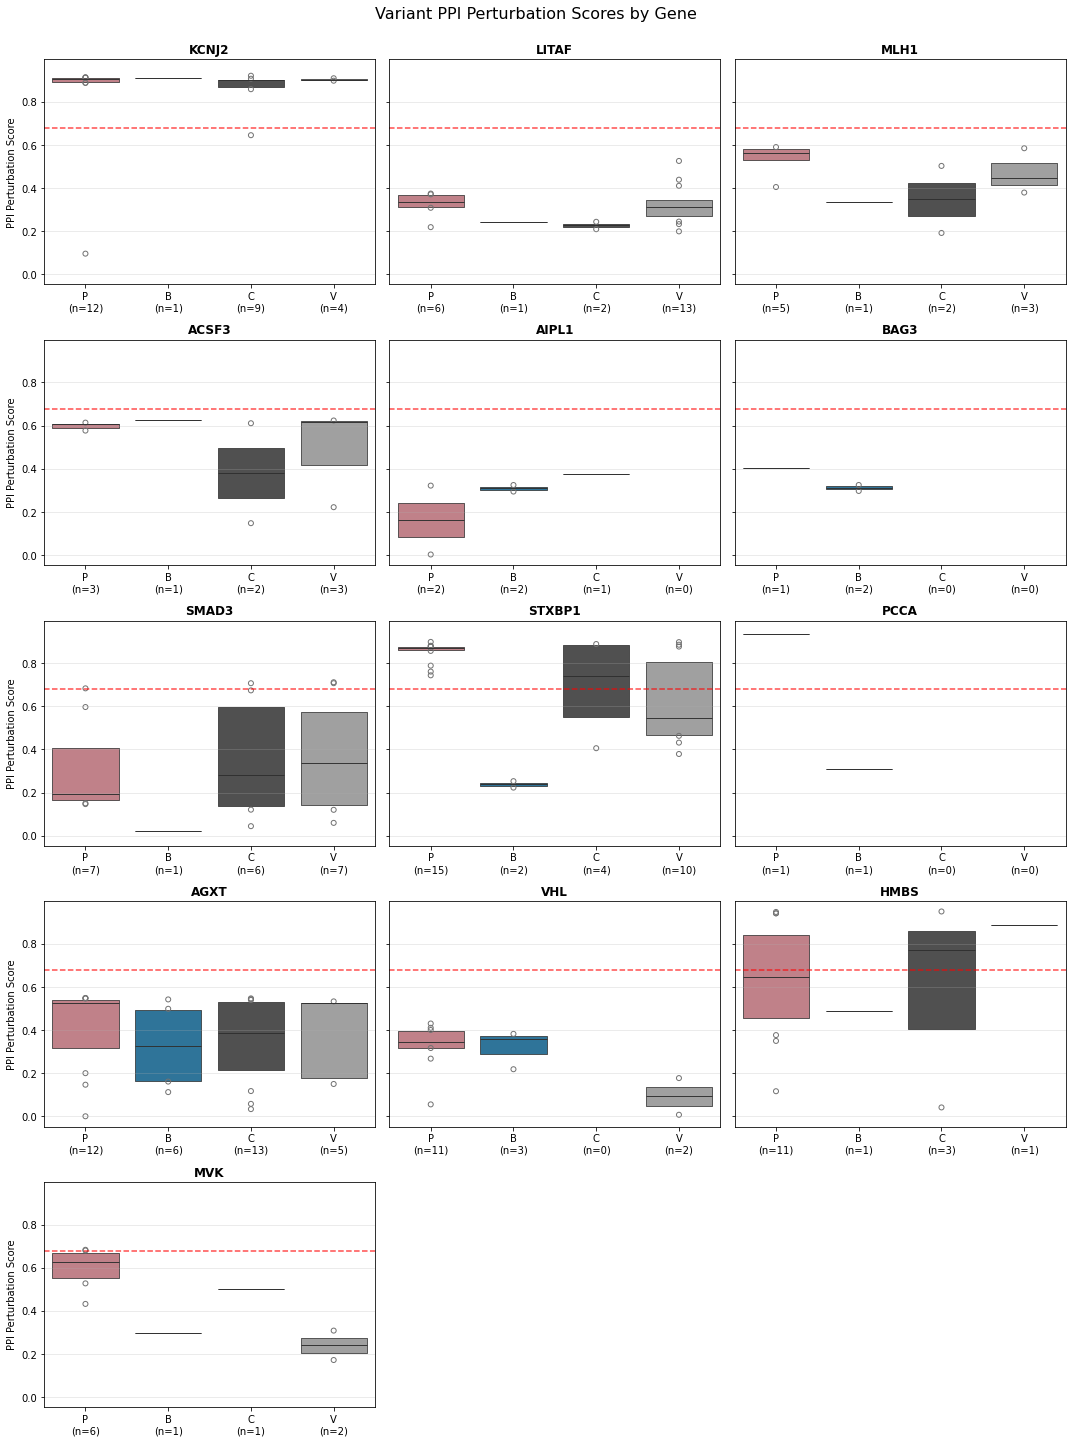

In [443]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxenplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Count variants per category and create labels with counts
        labels_with_counts = []
        for cat, label in zip(category_order, category_labels):
            count = len(gene_df[gene_df["clinvar_clnsig_clean"] == cat])
            labels_with_counts.append(f"{label}\n(n={count})")
        
        ax.set_xticklabels(labels_with_counts, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)
No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. A

No significant comparisons found at alpha=0.05 (FDR-corrected)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/1982390700.py:74: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels_with_counts, rotation=0)


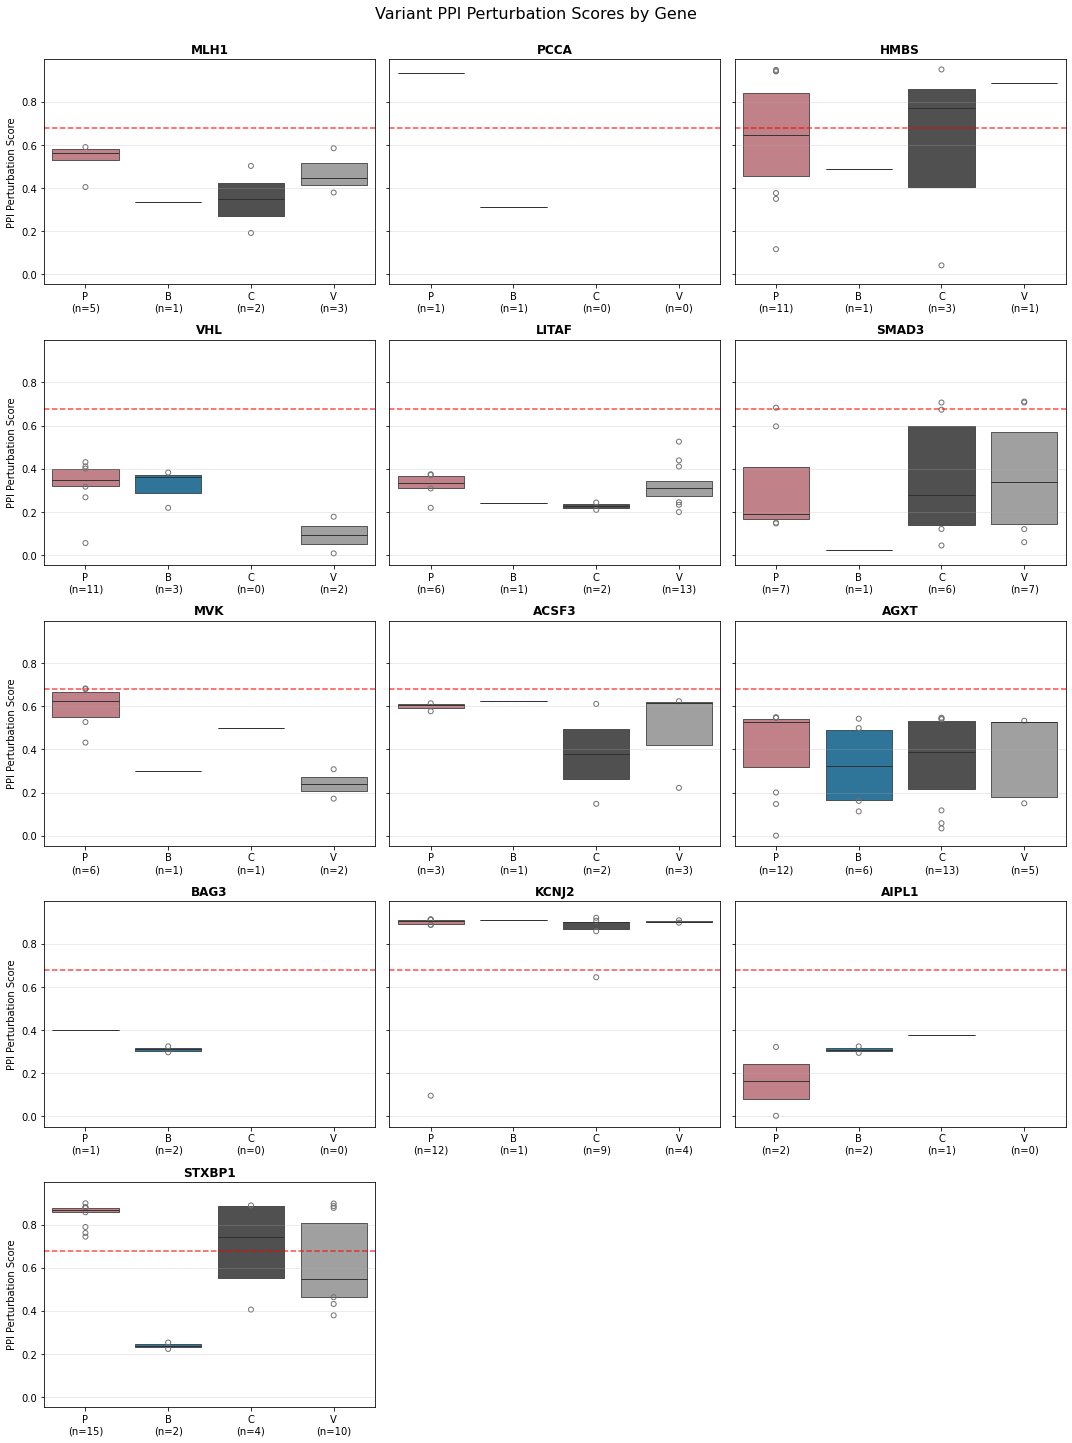

In [465]:
# Collect all data for genes that have both pathogenic and benign variants
plot_data = []
gene_order = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        df_pd = df.to_pandas()
        df_pd['symbol'] = gene
        plot_data.append(df_pd)
        gene_order.append(gene)

# Define fixed order for categories
category_order = ["Pathogenic","Benign", "Conflicting", "VUS"]
category_labels = ["P","B", "C", "V"]

# Create subplots
if plot_data:
    n_genes = len(gene_order)
    n_cols = 3  # Number of columns in the subplot grid
    n_rows = int(np.ceil(n_genes / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows), sharey=True)
    axes = axes.flatten() if n_genes > 1 else [axes]
    
    for idx, gene in enumerate(gene_order):
        ax = axes[idx]
        
        # Filter data for this gene
        gene_df = plot_data[idx]
        
        # Create boxplot for this gene with categories on x-axis
        sns.boxenplot(
            data=gene_df,
            x="clinvar_clnsig_clean",
            y="normalized_euclid_distance_normalized",
            order=category_order,
            palette=palette_dict["clinvar_clnsig_clean"],
            ax=ax
        )
        
        # Add statistical annotations
        add_statistical_annotations(
            ax=ax,
            data=pl.DataFrame(gene_df),
            x_col="clinvar_clnsig_clean",
            y_col="normalized_euclid_distance_normalized",
            order=category_order,
            test='mannwhitneyu',
            comparisons='all_significant',
            alpha=0.05,
            y_offset_factor=0.03,  # Smaller offset for subplots
            fontsize=8,  # Smaller font for subplots,
            fdr_correction=True
        )
        
        ax.axhline(y=0.678, color='red', linestyle='--', alpha=0.7)
        ax.set_title(f'{gene}', fontweight='bold')
        ax.set_ylabel("PPI Perturbation Score")
        ax.set_xlabel("")
        
        # Count variants per category and create labels with counts
        labels_with_counts = []
        for cat, label in zip(category_order, category_labels):
            count = len(gene_df[gene_df["clinvar_clnsig_clean"] == cat])
            labels_with_counts.append(f"{label}\n(n={count})")
        
        ax.set_xticklabels(labels_with_counts, rotation=0)
        ax.grid(alpha=0.3, axis='y')
    
    # Hide empty subplots
    for idx in range(n_genes, len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle('Variant PPI Perturbation Scores by Gene', fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()
else:
    print("No genes found with both pathogenic and benign variants")

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 212
Total unique db_orf_id: 13
Total Pathogenic variants: 92
Total Benign variants: 23


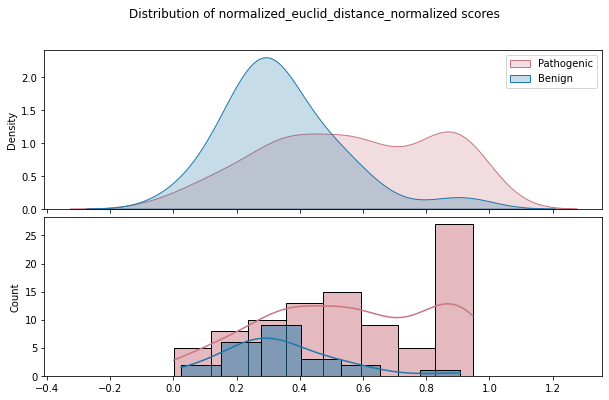

In [427]:
path_ben_genes = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_pathogenic and has_benign:
        path_ben_genes.append(gene)
        
orf_distances_path_ben = orf_distances.filter(
    pl.col("symbol").is_in(path_ben_genes)
)

plot_patho_benign(orf_distances_path_ben)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/630350873.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/630350873.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


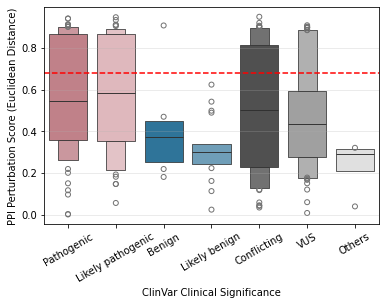

In [386]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/546843212.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/546843212.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


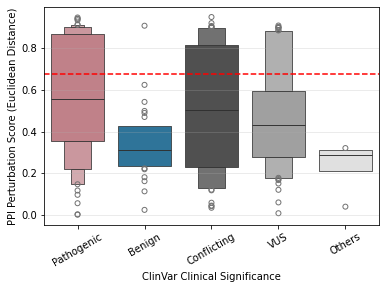

In [428]:

order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2798752247.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2798752247.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


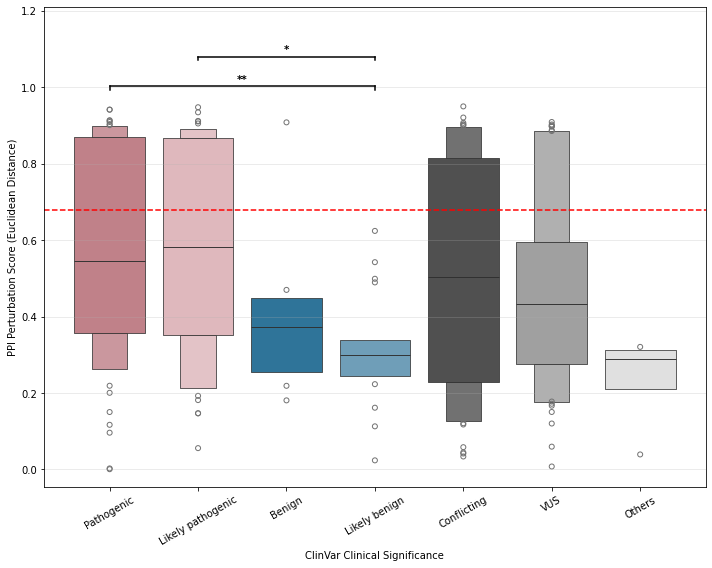


Significant Statistical Test Results (FDR-corrected, alpha=0.05)
Total comparisons: 21
Significant comparisons (FDR): 2
Significant comparisons (unadjusted): 6

Pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 711.0000
  P-value: 3.6944e-04
  P-value (FDR-adjusted): 7.7582e-03
  Reject null (FDR): True
  N1: 53, N2: 17
  Mean1: 0.5617, Mean2: 0.3155
  Median1: 0.5466, Median2: 0.2991
  Mean difference: 0.2463
  Significance: ** (very significant)

Likely pathogenic vs Likely benign:
  Test: Mann-Whitney U
  Statistic: 515.0000
  P-value: 1.1103e-03
  P-value (FDR-adjusted): 1.1658e-02
  Reject null (FDR): True
  N1: 39, N2: 17
  Mean1: 0.5693, Mean2: 0.3155
  Median1: 0.5832, Median2: 0.2991
  Mean difference: 0.2539
  Significance: * (significant)



In [452]:
order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances_path_ben,
    x_col="clinvar_clnsig_clean_pp_strict",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05  # Can adjust significance threshold
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
# print_statistical_summary(results, verbose=True, show_all=True)

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/677254777.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/677254777.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


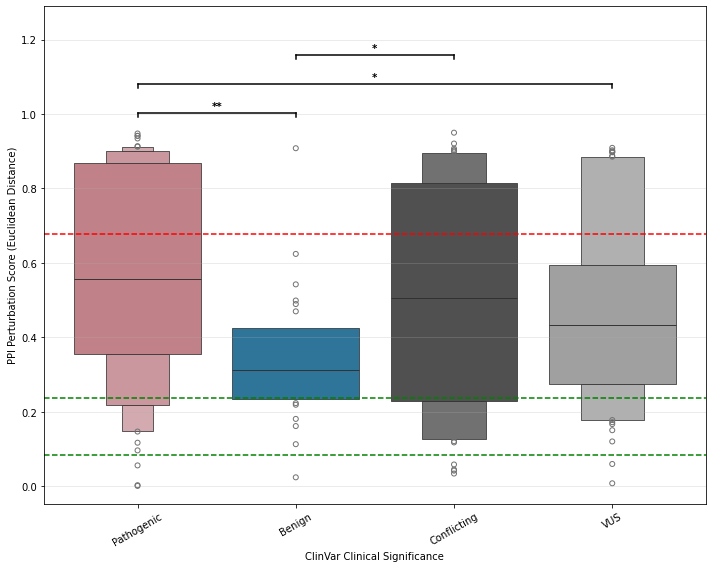


Significant Statistical Test Results (FDR-corrected, alpha=0.05)
Total comparisons: 6
Significant comparisons (FDR): 3
Significant comparisons (unadjusted): 3

Pathogenic vs Benign:
  Test: Mann-Whitney U
  Statistic: 1585.0000
  P-value: 2.3204e-04
  P-value (FDR-adjusted): 1.3922e-03
  Reject null (FDR): True
  N1: 92, N2: 23
  Mean1: 0.5650, Mean2: 0.3428
  Median1: 0.5567, Median2: 0.3115
  Mean difference: 0.2222
  Significance: ** (very significant)

Pathogenic vs VUS:
  Test: Mann-Whitney U
  Statistic: 2845.0000
  P-value: 2.0038e-02
  P-value (FDR-adjusted): 4.4307e-02
  Reject null (FDR): True
  N1: 92, N2: 50
  Mean1: 0.5650, Mean2: 0.4560
  Median1: 0.5567, Median2: 0.4336
  Mean difference: 0.1090
  Significance: * (significant)

Benign vs Conflicting:
  Test: Mann-Whitney U
  Statistic: 324.0000
  P-value: 2.2153e-02
  P-value (FDR-adjusted): 4.4307e-02
  Reject null (FDR): True
  N1: 23, N2: 43
  Mean1: 0.3428, Mean2: 0.5097
  Median1: 0.3115, Median2: 0.5046
  Mean dif

In [453]:
order = ["Pathogenic", "Benign", "Conflicting", "VUS"]#, "Others"]

fig, ax = plt.subplots(figsize=(10, 8))

sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean"],
    ax=ax
)

# Test ALL possible combinations and show only significant ones
results = add_statistical_annotations(
    ax=ax,
    data=orf_distances_path_ben,
    x_col="clinvar_clnsig_clean",
    y_col="normalized_euclid_distance_normalized",
    order=order,
    test='mannwhitneyu',
    comparisons='all_significant',  # This tests all pairs and shows only significant
    alpha=0.05,  # Can adjust significance threshold
    fdr_correction=True
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.axhline(y=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
ax.axhline(y=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.axhline(y=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.tight_layout()
plt.show()

# Print only significant results
print_statistical_summary(results, verbose=True, show_all=False)

# Or print all results
# print_statistical_summary(results, verbose=True, show_all=True)

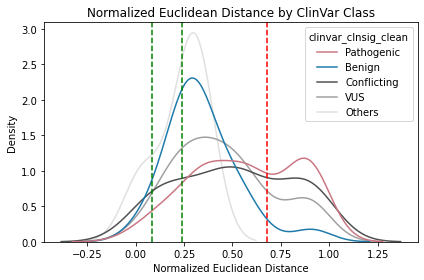

In [457]:
hue_order = ["Pathogenic", "Benign", "Conflicting", "VUS", "Others"]

sns.kdeplot(
    data=orf_distances_path_ben,
    x='normalized_euclid_distance_normalized',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.axvline(x=0.678, color='red', linestyle='--', label='LLR Threshold (0.678)')
plt.axvline(x=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.axvline(x=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

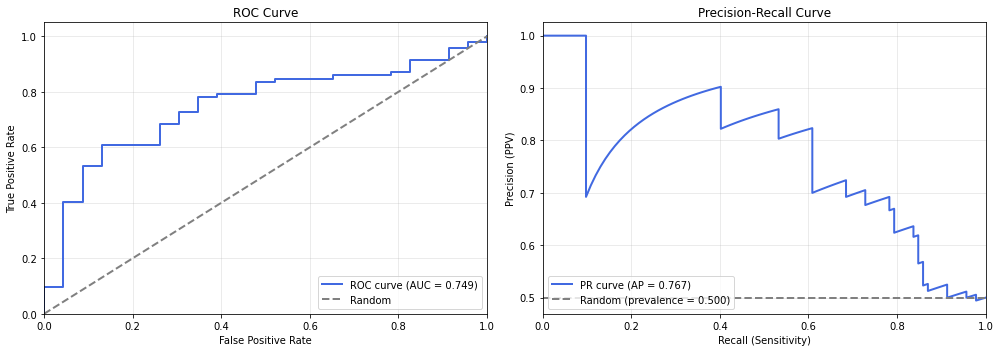

{'auroc': 0.7490548204158791,
 'auprc': 0.7674133442984252,
 'optimal_threshold': -0.523639993189881,
 'sensitivity': 0.6086956521739131,
 'specificity': 0.8695652173913043,
 'precision': 0.8235294117647058,
 'npv': 0.6896551724137931,
 'accuracy': 0.7391304347826086,
 'n_variants': 184,
 'n_pathogenic': 92,
 'n_benign': 92,
 'fpr': array([0.        , 0.        , 0.        , 0.04347826, 0.04347826,
        0.08695652, 0.08695652, 0.13043478, 0.13043478, 0.26086957,
        0.26086957, 0.30434783, 0.30434783, 0.34782609, 0.34782609,
        0.39130435, 0.39130435, 0.47826087, 0.47826087, 0.52173913,
        0.52173913, 0.65217391, 0.65217391, 0.7826087 , 0.7826087 ,
        0.82608696, 0.82608696, 0.91304348, 0.91304348, 0.95652174,
        0.95652174, 1.        , 1.        ]),
 'tpr': array([0.        , 0.01086957, 0.09782609, 0.09782609, 0.40217391,
        0.40217391, 0.5326087 , 0.5326087 , 0.60869565, 0.60869565,
        0.68478261, 0.68478261, 0.72826087, 0.72826087, 0.7826087 ,
 

In [431]:
evaluate_classification_performance(orf_distances_path_ben,
    clinvar_col="clinvar_clnsig_clean_pp_strict",
    metric_col="normalized_euclid_distance_normalized",
    balance_dataset=True
)

## LLR path ben

In [387]:
orf_distances_path_ben.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Benign", "Likely pathogenic", "Likely benign"])
).with_columns(
    pl.when(
        pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
    )
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "gene_variant", "clinvar_clnsig_clean_pp_strict"])
).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv")

orf_distances_path_ben.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("gene_variant").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv")

In [388]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_bcv.log" --bandwidth "bcv" --printTransitions  --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_default.log" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_nrd.log" --bandwidth "nrd" --printTransitions --kernel "gaussian" --outlierSuppression 0.1
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_allScores.csv ../3_outputs/sqY2H/calcLLR/scores/PPI_Best_Media_pb_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_sj.log" --printTransitions --bandwidth "SJ" --kernel "gaussian" --outlierSuppression 0.1

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-20_14:25:20 INFO: Reading input 
2025-11-20_14:25:20 INFO: Calculating densties 


Warning messages:
1: In stats::bw.bcv(data) : minimum occurred at one end of the range
2: In stats::bw.bcv(data) : minimum occurred at one end of the range
3: In stats::bw.bcv(data) : minimum occurred at one end of the range
4: In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-11-20_14:25:21 INFO: Drawing LLR plot 
2025-11-20_14:25:21 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-20_14:25:21 INFO: Category transitions:  
0.083 : none -> benign.support
0.328 : benign.support -> none
0.639 : none -> patho.support
0.731 : patho.support -> patho.moderate
2025-11-20_14:25:21 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-20_14:25:21 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_bcv.csv 
2025-11-20_14:25:21 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-11-20_14:25:24 INFO: Reading input 
2025-11-20_14:25:24 INFO: Calculating densties 
2025-11-20_14:25:25 INFO: Drawing LLR plot 
2025-11-20_14:25:25 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-20_14:25:25 INFO: Category transitions:  
0.037 : none -> benign.support
0.114 : benign.support -> none
0.173 : none -> benign.support
0.308 : benign.support -> none
0.436 : none -> benign.support
0.498 : benign.support -> none
0.539 : none -> patho.support
0.610 : patho.support -> none
0.668 : none -> patho.support
0.797 : patho.support -> none
0.813 : none -> patho.support
0.830 : patho.support -> patho.moderate
2025-11-20_14:25:25 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-20_14:25:25 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_default.csv 
2025-11-20_14:25:25 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-20_14:25:26 INFO: Reading input 
2025-11-20_14:25:26 INFO: Calculating densties 
2025-11-20_14:25:27 INFO: Drawing LLR plot 
2025-11-20_14:25:27 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-20_14:25:27 INFO: Category transitions:  
0.120 : none -> benign.support
0.353 : benign.support -> none
0.626 : none -> patho.support
0.692 : patho.support -> patho.moderate
2025-11-20_14:25:27 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-20_14:25:27 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_nrd.csv 
2025-11-20_14:25:27 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-20_14:25:28 INFO: Reading input 
2025-11-20_14:25:28 INFO: Calculating densties 
2025-11-20_14:25:29 INFO: Drawing LLR plot 
2025-11-20_14:25:29 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-11-20_14:25:29 INFO: Category transitions:  
0.169 : none -> benign.support
0.318 : benign.support -> none
0.451 : none -> benign.support
0.482 : benign.support -> none
0.567 : none -> patho.support
0.701 : patho.support -> patho.moderate
2025-11-20_14:25:29 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-11-20_14:25:29 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/output/PPI_Best_Media_pb_LLR_score_sj.csv 
2025-11-20_14:25:29 INFO: Done! 


In [ ]:
0.083 : none -> benign.support
0.328 : benign.support -> none
0.639 : none -> patho.support
0.731 : patho.support -> patho.moderate

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2817514769.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_16809/2817514769.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


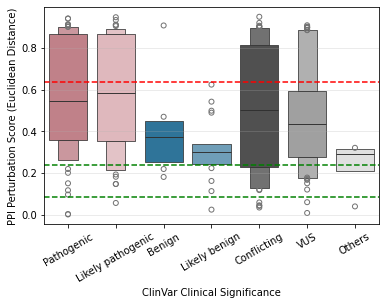

In [389]:

order = ["Pathogenic", "Likely pathogenic", "Benign", "Likely benign", "Conflicting", "VUS", "Others"]

ax = sns.boxenplot(
    data=orf_distances_path_ben,
    x="clinvar_clnsig_clean_pp_strict",
    y="normalized_euclid_distance_normalized",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pp_strict"],
)

ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
plt.axhline(y=0.639, color='red', linestyle='--', label='LLR Threshold (0.620)')
plt.axhline(y=0.083, color='green', linestyle='--', label='LLR Threshold (0.620)')
plt.axhline(y=0.238, color='green', linestyle='--', label='LLR Threshold (0.620)')
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 212
Total unique db_orf_id: 13
Total Pathogenic variants: 92
Total Benign variants: 23
fixed_threshold: 0.639


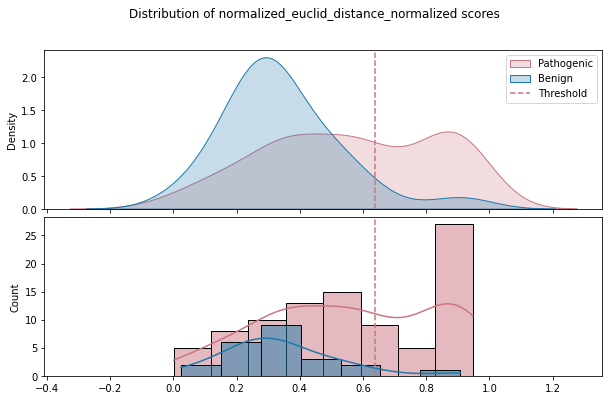

Benign: 1 (4.35%)
Pathogenic: 36 (39.13%)
VUS: 10 (20.00%)
Conflicting: 15 (34.88%)


In [390]:
plot_patho_benign(orf_distances_path_ben, fixed_threshold=0.639)

In [349]:
orf_distances_path_ben

db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,seq,seq_aa,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,…,g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
i64,i64,f64,i64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool
11805,2167,0.476382,2,0.336853,0.364237,"""SMAD3""","""ENSG00000166949""","""CCSBVarC007743""","""ALE00007729""","""NC_000015.10:67184823:G:A""","""968G>A""","""Arg323His""","""ATGTCGTCCATCCTGCCTTTCACTCCCCCG…","""MSSILPFTPPIVKRLLGWKKGEQNGQEEKW…","""Edgotyping3""","""VUSMutGDEh005""","""A04""","""GDEhDisVCh_40014""","""F10""",2.0,"""VUSMutGDDh005""","""A04""","""VUSN2Hmut_GDN2h_02""","""B01""","""VUSMutpDEST2_09""","""E06""","""VUSmut_GDEh02""","""B01""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,-55.7,null,null,null,-37.0,"""Sufficient for interaction wit…",null,null,null,null,"""H (helix)""","""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,96.89,25.403225,""">90""","""10-90""",null,null,null,"""Rare genetic vascular disease;…",2,null,false
5066,201832,1.08342,13,0.300487,0.324914,"""BAG3""","""ENSG00000151929""","""CCSBVarC003585""","""ALE00003585""","""NC_000010.11:119676692:C:T""","""1138C>T""","""Pro380Ser""","""ATGAGCGCCGCCACCCACTCGCCCATGATG…","""MSAATHSPMMQVASGNGDRDPLPPGWEIKI…","""CEGS2""","""CegsMutGDEh1038""","""B01""","""GDEhDisVCh_40022""","""E08""",2.0,"""CegsMutGDDh1038""","""B01""","""VUSN2Hmut_GDN2h_07""","""A10""","""VUSMutpDEST2_04""","""D12""","""VUSmut_GDEh07""","""A10""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,-136.6,null,null,null,-177.8,"""Disordered""",null,null,"""dbSNP: rs144692954; Variant ty…",null,"""C (loop/coil)""","""C (loop/coil)""",null,null,null,null,null,null,null,null,null,null,null,57.85,94.117645,"""50-70""","""$\geqslant$90""","""612954;613881;612954""","""autosomal dominant""","""OMIM""","""Rare genetic cardiac disease; …",2,"""MYOPATHY, MYOFIBRILLAR, 6; CAR…",false
2803,200940,0.323706,1,0.323706,0.350021,"""HMBS""","""ENSG00000256269""","""CCSBVarC005177""","""ALE00005177""","""NC_000011.10:119092518:C:A""","""766C>A""","""His256Asn""","""ATGTCTGGTAACGGCAATGCGGCTGCAACG…","""MSGNGNAAATAEENSPKMRVIRVGTRKSQL…","""CEGS2""","""CegsMutGDEh1042""","""G06""","""GDEhDisVCh_40054""","""F07""",2.0,"""CegsMutGDDh1042""","""G06""",null,null,null,null,null,null,1.0,1.0,1.0,1.0,0.0,null,null,0.0,…,null,null,null,-74.3,null,null,null,-28.6,null,null,null,null,null,"""H (helix)""","""H (α-helix)""","""Helix""",null,null,null,null,null,null,null,null,null,null,96.92,39.130436,"

Plotting normalized_euclid_distance_normalized distribution for Pathogenic and Benign variants
Total variants: 22
Total unique db_orf_id: 4
Total Pathogenic variants: 0
Total Benign variants: 8


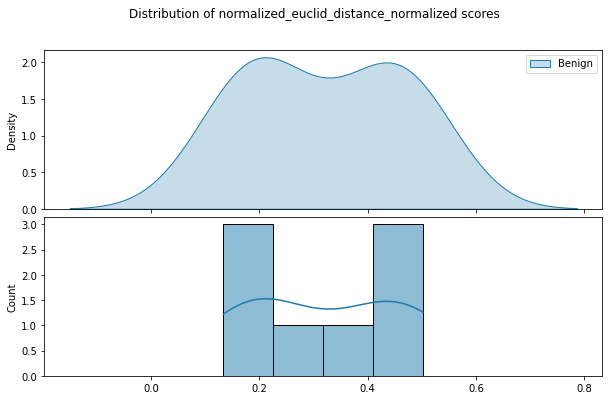

In [458]:
# has benign and no pathogenic
# has benign and no pathogenic
benign_no_path_genes = []

for gene_tuple in orf_distances.group_by("symbol"):
    gene = gene_tuple[0][0]  # First element is the gene name
    df = gene_tuple[1]     # Second element is the dataframe
    
    clinvar_classes = df["clinvar_clnsig_clean_pp_strict"].unique()
    has_pathogenic = any(x in clinvar_classes for x in ["Pathogenic", "Likely pathogenic"])
    has_benign = any(x in clinvar_classes for x in ["Benign", "Likely benign"])
    
    if has_benign and not has_pathogenic:
        benign_no_path_genes.append(gene)
        
orf_distances_benign_no_path = orf_distances.filter(
    pl.col("symbol").is_in(benign_no_path_genes)
)

plot_patho_benign(orf_distances_benign_no_path)

In [460]:
orf_distances_benign_no_path.to_pandas().db_orf_id.unique()

array([54308, 14966,  3438,  3980])

# test

In [467]:
orf_distances.to_pandas()

,db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,ensembl_gene_id,ccsb_mutation_id,ccsb_allele_id,...,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
0,4062,201429,1.472717,16,0.368179,0.398109,PLP1,ENSG00000123560,CCSBVarC005858,ALE00005858,...,13.076923,>90,10-90,312920,x-linked recessive,OMIM,Rare genetic eye disease; Rare genetic neurolo...,2,"SPASTIC PARAPLEGIA 2, X-LINKED",False
1,7652,1798,1.573575,5,0.703724,0.760931,STXBP1,ENSG00000136854,CCSBVarC001220,ALE00001220,...,0.000000,>90,<10,612164,autosomal dominant,OMIM,Rare genetic developmental defect during embry...,5,DEVELOPMENTAL AND EPILEPTIC ENCEPHALOPATHY 4,False
2,4062,201426,2.309728,16,0.577432,0.624373,PLP1,ENSG00000123560,CCSBVarC005859,ALE00005859,...,33.802814,>90,10-90,312080,x-linked recessive,OMIM,Rare genetic eye disease; Rare genetic neurolo...,2,PELIZAEUS-MERZBACHER DISEASE,False
3,7652,1832,1.821242,5,0.814484,0.880696,STXBP1,ENSG00000136854,CCSBVarC007651,ALE00007637,...,7.317073,>90,<10,None,None,None,Rare genetic developmental defect during embry...,5,None,False
4,7167,12744,0.296622,1,0.296622,0.320736,AIPL1,ENSG00000129221,CCSBVarC001133,ALE00001133,...,0.000000,>90,<10,None,None,None,Rare genetic eye disease; Ciliopathy,2,None,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,8143,202839,0.118606,2,0.083867,0.090685,SH3BP2,ENSG00000087266,CCSBVarC003712,ALE00003712,...,89.705890,50-70,10-90,118400,autosomal dominant,OMIM,Rare genetic immune disease; Rare genetic deve...,3,CHERUBISM,False
485,13320,204009,0.293265,1,0.293265,0.317106,VHL,ENSG00000134086,CCSBVarC006544,ALE00006543,...,32.394367,>90,10-90,193300,autosomal dominant,OMIM,Rare genetic eye disease; Rare genetic renal d...,8,VON HIPPEL-LINDAU SYNDROME,False
486,3980,201374,0.480536,7,0.181626,0.196390,GRN,ENSG00000030582,CCSBVarC004641,ALE00004641,...,22.962963,70-90,10-90,None,None,None,Rare genetic eye disease; Rare genetic neurolo...,3,None,False
487,8151,202846,0.052217,2,0.036923,0.039924,IL36RN,ENSG00000136695,CCSBVarC006167,ALE00006167,...,0.000000,>90,<10,614204,autosomal recessive,OMIM,Rare genetic immune disease; Rare genetic skin...,2,"PSORIASIS 14, PUSTULAR",False


In [471]:
df_pd = df.to_pandas()

df_pd[(df_pd['symbol'] == 'AGXT') &
      (df_pd.db_mut_id == 3792)]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
468,VUSAPWT1B1r05_007,O09,VUSAPWT1B1r05_007_008_009_010_011_012,VUSAPWT1B1,r11,LWH25,1,False,13662,NaN,...,70497.0_3792.0_LWH25_VUSAPWT1B1,13662.0_70497.0_3792.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,Y,10.042654,2.0,357.210909,-0.002054


In [472]:
df_pd[(df_pd['symbol'] == 'AGXT') &
      (df_pd.db_mut_id == 0)]

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final_right,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc
451,VUSAPWT1B1r05_001,A17,VUSAPWT1B1r05_001_002_003_004_005_006,VUSAPWT1B1,r11,LWH25,1,False,13662,NaN,...,70497.0_0.0_LWH25_VUSAPWT1B1,13662.0_70497.0_0.0_VUSAPWT1B1,13662.0_70497.0_VUSAPWT1B1,1,1,None,4.621615,2.0,357.210909,0.0


In [474]:
np.sqrt(0.5)

0.7071067811865476

In [483]:
diff_squared = np.array(((356.70/750) - (357.21/750)) ** 2)
distances = np.sqrt(diff_squared.sum())

distances

0.0006800000000000139

In [482]:
profiles[70497]

ad_orf_id,0,3782,3785,3780,205584,205586,205592,3796,3812,3867,3814,3786,3872,3789,3805,3873,3791,3792,3818,3828,3821,3835,3826,3815,3857,3876,3848,3878,3882,3858,3879,3843,3850,3863,3888,3851,3874,3881,3889
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
13662,0.512068,0.005992,0.012761,0.026105,0.004218,0.407645,0.050634,0.063788,0.004958,0.010487,0.375995,0.077546,0.024372,0.013235,0.006601,0.458105,0.015874,0.511337,0.676451,0.651216,0.026727,0.661536,0.167391,0.178883,0.48059,0.018902,0.18067,0.023966,0.00927,0.620911,0.679301,0.16951,0.027795,0.711678,0.045381,0.697606,0.021719,0.054765,0.87085
